# **A Machine Learning Approach to Predicting In-Hospital ICU Mortality**

*Sammy, Hoi & Andrew — Harvard CS1090a / CS109a final project, Fall 2025*

**Running this notebook**
- Sections 3–5 only need `data/training_v2.csv`.
- Section 6 reads the splits in `data/preprocessed/12-01/`, produced by `02_preprocessing.ipynb`, so it can run on its own.
- The Bayesian models load from `data/bayesian_model_checkpoints/` if present; sampling from scratch needs a GPU (JAX/NumPyro) and a lot of patience.

See the repo README for where to get the data.

# Table of Contents
- [1. Research Question](#question)
- [2. Problem Description](#problem)
- [3. Our Dataset](#data)
- [4. Data Cleaning](#cleaning)
- [5. Feature Selection](#preprocessing)
- [6. Modelling](#modelling)
- [7. Evaluation](#evaluation)

<a id="question"></a>
## **1. Research Question**

*What is the minimal set of non-redundant, 24-hour clinical features (vitals, labs, demographics) that are the most impactful predictors of in-hospital ICU mortality? Furthermore, can this core set of features be used to train a reliable triage model that performs well despite the challenges of high class imbalance and data missingness?*

<a id="problem"></a>
## **2. Problem Description**

### The Clinical Challenge

Accurately predicting a patient's risk of death in the Intensive Care Unit (ICU) is a critical but difficult task. Real-world clinical decision-making is famously complex, and in the high-pressure ICU environment, it is easy to get lost in the plethora of available clinical data. This complexity highlights the urgent need for an interpretable and reliable predictive tool to support patient triage, resource allocation and early prognosis.

### The Data Science Challenge

The data science problem is to build a reliable and interpretable predictive model that can estimate this risk using only the data collected within the first 24 hours of an ICU admission. The model must be robust enough to handle the severe data quality challenges of a real-world clinical dataset, most notably extreme data missingness and high class imbalance.

In [84]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    classification_report,
    accuracy_score,
    roc_curve,
    auc,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from joblib import Parallel, delayed

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import lightgbm as lgb
import shap


import graphviz
import pickle
import cloudpickle
import pymc as pm
import arviz as az
from datetime import datetime


<a id="data"></a>
## 3. Our Dataset

We are using the `training_v2.csv` file from the **WiDS Datathon 2020** repository. This comprehensive clinical dataset contains:

- **91,713 ICU encounters** from 147 hospitals
- **185 clinical features** including vitals, laboratory values, and demographic information
- **Target variable:** `hospital_death` (in-hospital mortality)
- **Time scope:** Features captured within the first 24 hours of ICU admission


In [85]:
# Load metadata
df_meta = pd.read_csv("../data/WiDS Datathon 2020 Dictionary.csv")
df_meta = df_meta[~df_meta["Variable Name"].isin(["icu_admit_type", "pred"])]

# Load data
df = pd.read_csv("../data/training_v2.csv")


### 3.1 EDA (Pre-Cleaning)

### Brief Data Overview
The data is overwhelmingly numeric (171 float64 columns) with a few categorical (object) features. All features were captured within the first 24 hours of a patient's ICU stay and include demographics, vital signs, laboratory values, and APACHE covariates, which are metrics from the APACHE IVa scoring system.

With our initial exploration, we found a couple of interesting findings:
- **Feature Complexity**: The dataset is highly complex, with over 180 features and significant multicollinearity, as visualized in the correlation heatmap (Fig. 1). This finding directs our methodology toward regularization techniques, like Lasso, to perform automatic feature selection.
- **Class Imbalance**: The target variable, hospital_death, is highly imbalanced, with a 10.6-to-1 survivor-to-death ratio (Fig. 2). This imbalance makes accuracy a misleading metric, as a 'naive' model that only predicts 'survive' would achieve over 91% accuracy. This finding necessitates using robust evaluation metrics (e.g., AUROC) and modeling strategies (e.g., class weighting).
- **Systematic Missingness**: Missing data is a core problem. A clear "two-camp" pattern emerged: 175 columns have missing values, but 74 of those are missing over 50% of their data. This systematic missingness informs our pipeline's strategy of dropping low-quality features to focus on a high-quality subset. Fortunately, none of the target variables is missing (Fig. 3). 
- **Inter-hospital variance**: There is wide inter-hospital variance in term of mortality rates. It strongly suggests that patient outcomes are dependent on which hospital they are in, not just their individual clinical features. This finding directly impacts our project direction, as it justifies exploring a hierarchical (or multilevel) logistic regression (Fig. 4).


In [86]:
# =============================================================================
# SUMMARY OF THE DATA
# =============================================================================

print("=" * 80)
print("                         WiDS DATATHON 2020 DATASET SUMMARY")
print("=" * 80)


print(f"\nDATASET SHAPE")
print(f"   Rows (patients): {df.shape[0]:,}")
print(f"   Columns (features): {df.shape[1]:,}")
print(f"   Total data points: {df.shape[0] * df.shape[1]:,}")

# Target variable distribution
target_counts = df["hospital_death"].value_counts().sort_index()
print(f"\nTARGET VARIABLE (hospital_death)")
print(
    f"   • Survivors (0): {target_counts[0]:,} ({target_counts[0] / len(df) * 100:.1f}%)"
)
print(
    f"   • Deaths (1): {target_counts[1]:,} ({target_counts[1] / len(df) * 100:.1f}%)"
)
print(f"   • Class imbalance ratio: {target_counts[0] / target_counts[1]:.1f}:1")

# Data types breakdown
dtype_counts = df.dtypes.value_counts()
print(f"DATA TYPES BREAKDOWN")
for dtype, count in dtype_counts.items():
    print(f"   • {dtype}: {count} columns")


missing_stats = df.isnull().sum()
total_missing = missing_stats.sum()
cols_with_missing = (missing_stats > 0).sum()
print(f"\nMISSING DATA OVERVIEW")
print(f"   Total missing values: {total_missing:,}")
print(f"   Columns with missing data: {cols_with_missing}/{len(df.columns)}")
print(
    f"   Overall missingness rate: {total_missing / (df.shape[0] * df.shape[1]) * 100:.1f}%"
)
print(f"   Columns with >50% missing: {(missing_stats > len(df) * 0.5).sum()}")
print(f"   Columns with >75% missing: {(missing_stats > len(df) * 0.75).sum()}")


print(f"\nKEY IDENTIFIERS")
print(f"   Unique patients: {df['patient_id'].nunique():,}")
print(f"   Unique encounters: {df['encounter_id'].nunique():,}")
print(f"   Unique hospitals: {df['hospital_id'].nunique():,}")
print(f"   Unique ICUs: {df['icu_id'].nunique():,}")

print("\n" + "=" * 80)

# Define column types based on metadata
col_types = {}
types_col = defaultdict(set)

for _, row in df_meta.iterrows():
    types_col[row["Data Type"]].add(row["Variable Name"])
    col_types[row["Variable Name"]] = row["Data Type"]

col_types["bmi"] = "numeric"
types_col["numeric"].add("bmi")
types_col["string"].remove("bmi")


                         WiDS DATATHON 2020 DATASET SUMMARY

DATASET SHAPE
   Rows (patients): 91,713
   Columns (features): 186
   Total data points: 17,058,618

TARGET VARIABLE (hospital_death)
   • Survivors (0): 83,798 (91.4%)
   • Deaths (1): 7,915 (8.6%)
   • Class imbalance ratio: 10.6:1
DATA TYPES BREAKDOWN
   • float64: 170 columns
   • int64: 8 columns
   • object: 8 columns

MISSING DATA OVERVIEW
   Total missing values: 5,743,492
   Columns with missing data: 175/186
   Overall missingness rate: 33.7%
   Columns with >50% missing: 74
   Columns with >75% missing: 45

KEY IDENTIFIERS
   Unique patients: 91,713
   Unique encounters: 91,713
   Unique hospitals: 147
   Unique ICUs: 241



#### Figure 1: Correlation Heatmap of Predictor Variables

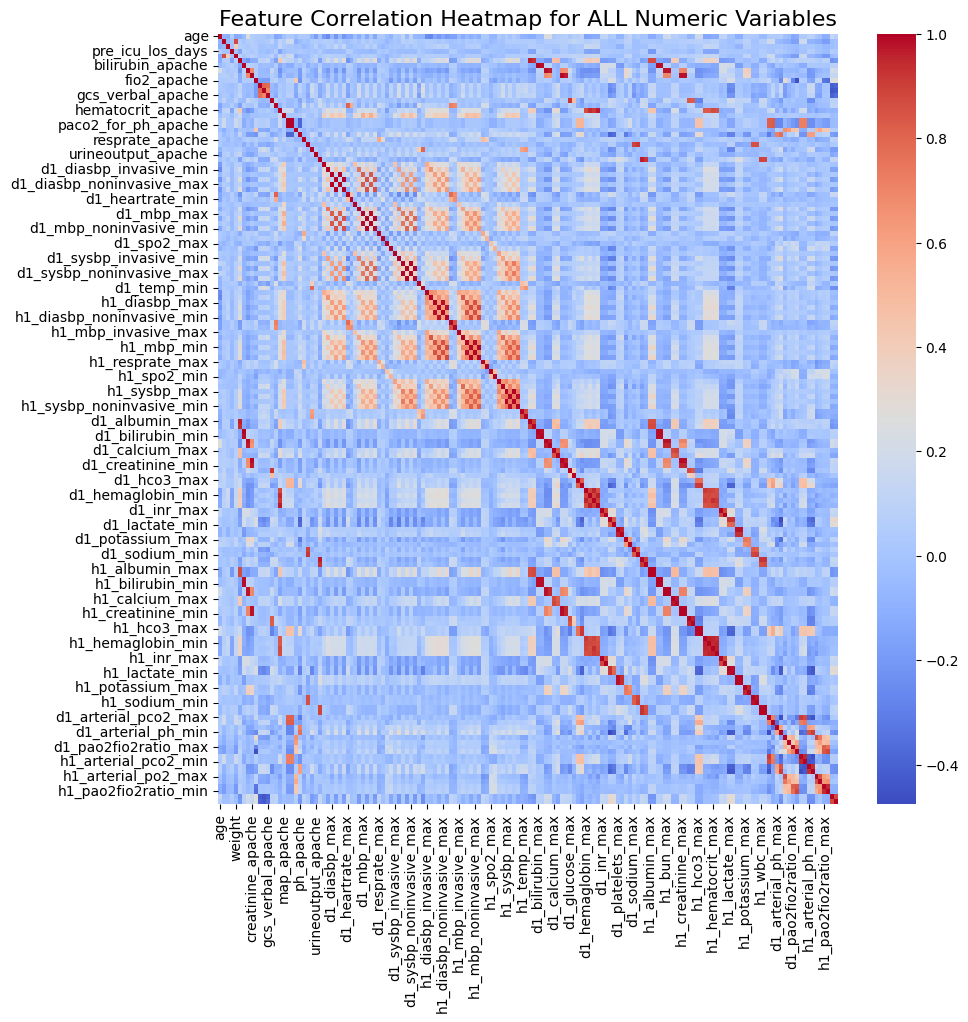

In [87]:
all_numeric_cols = [
    col
    for col in df.columns
    if col in col_types and col_types[col] in ("integer", "numeric")
]

cols_to_exclude = [
    "encounter_id",
    "patient_id",
    "hospital_id",
    "icu_id",
    "hospital_death",
]
numeric_cols_for_corr = [col for col in all_numeric_cols if col not in cols_to_exclude]

correlation_matrix = df[numeric_cols_for_corr].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", annot=False)
plt.title(
    "Feature Correlation Heatmap for ALL Numeric Variables", fontsize=16
)  # Updated title
plt.show()


#### Figure 2: Class imbalance in Target Variable

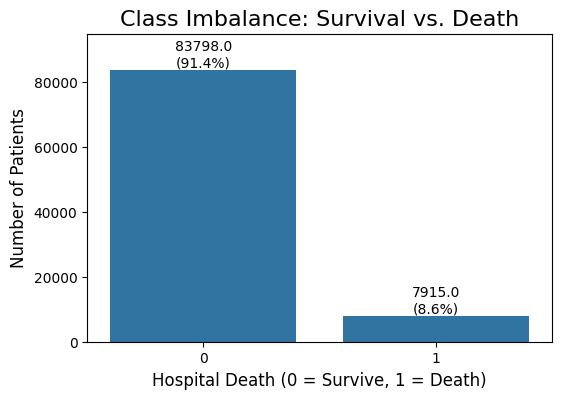

In [88]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="hospital_death", data=df)
plt.title("Class Imbalance: Survival vs. Death", fontsize=16)
plt.xlabel("Hospital Death (0 = Survive, 1 = Death)", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.ylim(0, 95000)
total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.0,
        height + 3,
        f"{height}\n({height / total:.1%})",
        ha="center",
        va="bottom",
    )
plt.show()


#### Figure 3: Systematic Missingness in Predictor Variables

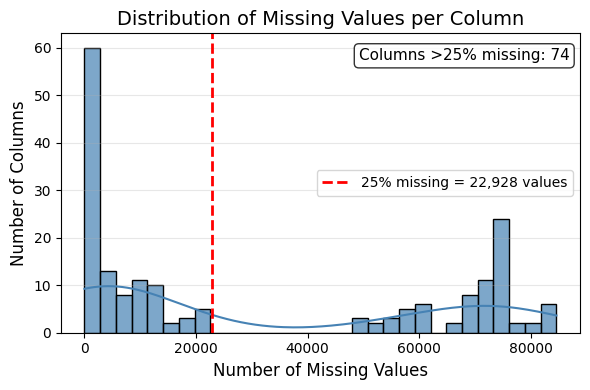

In [89]:
missing_counts = df.isnull().sum()
threshold = df.shape[0] * 0.25
n_exceed = (missing_counts > threshold).sum()

plt.figure(figsize=(6, 4))
ax = sns.histplot(
    missing_counts, bins=30, kde=True, color="steelblue", edgecolor="k", alpha=0.7
)
ax.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"25% missing = {int(threshold):,} values",
)
ax.set_title("Distribution of Missing Values per Column", fontsize=14)
ax.set_xlabel("Number of Missing Values", fontsize=12)
ax.set_ylabel("Number of Columns", fontsize=12)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# show count of columns above the threshold
ax.text(
    0.98,
    0.95,
    f"Columns >25% missing: {n_exceed}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
)

plt.tight_layout()
plt.show()


#### Figure 4: Distribution of Hospital Mortality Rates

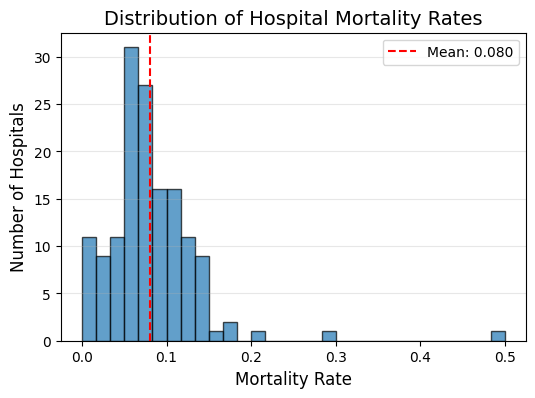

In [90]:
plt.figure(figsize=(6, 4))
all_hospital_stats = df.groupby("hospital_id")["hospital_death"].mean()
plt.hist(all_hospital_stats, bins=30, edgecolor="black", alpha=0.7)
plt.title("Distribution of Hospital Mortality Rates", fontsize=14)
plt.xlabel("Mortality Rate", fontsize=12)
plt.ylabel("Number of Hospitals", fontsize=12)
plt.axvline(
    all_hospital_stats.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {all_hospital_stats.mean():.3f}",
)
plt.legend()
plt.grid(axis="y", alpha=0.3)


<a id="cleaning"></a>
## **4. Data Preprocessing 1: Data Cleaning**

To clean our data, we first filtered out features with excessive missingness (>25%) to focus on higher-quality data, reducing the feature space from 182 to 112 columns. For the remaining missing values, we implemented a SimpleImputer for categorical features (filling with the most frequent value) and an IterativeImputer for numerical features (using multivariate imputation via chained equations). This approach allowed us to retain as much information as possible while addressing the challenges of missing data.

### 4.1. Dropping High-Missingness Columns and Creating Missingness Indicators

In [91]:
# Initial data cleaning: drop columns with >25% missing
df = df.drop(df.isnull().sum()[df.isnull().sum() > df.shape[0] * 0.25].index, axis=1)

df.shape


(91713, 112)

In [92]:
num_cols = set()
cat_cols = set()
for col in df.columns:
    if col_types[col] in ("integer", "numeric"):
        num_cols.add(col)
    else:
        cat_cols.add(col)


In [93]:
missingness_predictor_cols = []
ignored = [
    "hospital_id",
    "icu_idencounter_id",
    "patient_id",
    "hospital_death",
    "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob",
]
list_of_zero_missing_cols = df.columns[df.isnull().sum() == 0].to_list()
for col in list_of_zero_missing_cols:
    if col not in ignored:
        missingness_predictor_cols.append(col)

print(missingness_predictor_cols)


['encounter_id', 'elective_surgery', 'icu_id', 'icu_stay_type', 'icu_type', 'pre_icu_los_days', 'readmission_status', 'apache_post_operative']


In [94]:
# Add missingness indicator features
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[f"{col}_missing"] = df[col].isnull().astype(int)

df = df.copy()


In [95]:
X = df[missingness_predictor_cols]
missingness_indicator_cols = [col for col in df.columns if col.endswith("_missing")]
y_df = df[missingness_indicator_cols]

print(X.columns)


Index(['encounter_id', 'elective_surgery', 'icu_id', 'icu_stay_type',
       'icu_type', 'pre_icu_los_days', 'readmission_status',
       'apache_post_operative'],
      dtype='object')


### 4.2. Imputation with IterativeImputer

In [96]:
num_cols_list = list(num_cols)
cat_cols_list = list(cat_cols)

df_pre_impute = df.copy()

for col in cat_cols_list:
    if df_pre_impute[col].isnull().sum() > 0:
        imputer = SimpleImputer(strategy="most_frequent")
        df_pre_impute[col] = imputer.fit_transform(df_pre_impute[[col]])[:, 0]

# Impute numeric features with IterativeImputer
imputer = IterativeImputer(max_iter=10, random_state=42)
df_pre_impute[num_cols_list] = imputer.fit_transform(df_pre_impute[num_cols_list])

df_imputed = df_pre_impute.copy()


<a id="preprocessing"></a>
## **5. Data Preprocessing 2: Lasso Regression for Feature Selection**

Given the high dimensionality and multicollinearity of our dataset, we employed Lasso regression for feature selection. With Lasso, we hope to reduce the feature space to approximately 20-30 key features that are most predictive of mortality. 

Moreover, we hypothesized that extreme values of certain clinical features such as blood pressure and potassium levels are highly indicative of mortality risk (we call them 'Goldilock features', see full list in poly_cols). To allow the model to capture these non-linear effects, we created squared terms for these features for the Lasso. 


In [97]:
X = df_imputed.drop(columns=["hospital_death"] + ignored, errors="ignore")
y = df_imputed["hospital_death"]

num_cols_for_model = [
    col for col in num_cols if col in X.columns and col not in ignored
]
cat_cols_for_model = [
    col for col in cat_cols if col in X.columns and col not in ignored
]

poly_cols = [
    # Vitals
    "d1_heartrate_max",
    "d1_heartrate_min",
    "d1_sysbp_min",
    "d1_sysbp_max",
    "d1_mbp_min",
    "d1_mbp_max",
    "d1_temp_min",
    "d1_temp_max",
    "d1_resprate_min",
    "d1_resprate_max",
    "d1_spo2_min",
    # Labs
    "d1_potassium_max",
    "d1_potassium_min",
    "d1_glucose_max",
    "d1_glucose_min",
    "d1_sodium_max",
    "d1_sodium_min",
    "d1_wbc_max",
    "d1_wbc_min",
    "d1_hematocrit_max",
    "d1_hematocrit_min",
    "d1_calcium_max",
    "d1_calcium_min",
    # Demographics
    "age",
    "weight",
]


In [98]:
# Custom transformer to add squared features only
from sklearn.base import BaseEstimator, TransformerMixin


class SquaredFeaturesOnly(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        self.feature_names_in_ = getattr(
            X, "columns", [f"x{i}" for i in range(X.shape[1])]
        )
        return self

    def transform(self, X):
        # Convert to numpy if pandas
        X_array = X.values if hasattr(X, "values") else X

        # Add only squared terms, no interactions
        X_squared = X_array**2

        # Combine original and squared
        return np.hstack([X_array, X_squared])

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_

        # Original feature names + squared feature names
        original_names = list(input_features)
        squared_names = [f"{name}^2" for name in input_features]

        return np.array(original_names + squared_names)


In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "poly_goldilocks",
            Pipeline([("scaler", StandardScaler()), ("poly", SquaredFeaturesOnly())]),
            poly_cols,
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore", sparse_output=False, drop="if_binary"
            ),
            cat_cols_for_model,
        ),
        (
            "num",
            StandardScaler(),
            [c for c in num_cols_for_model if c not in poly_cols],
        ),
    ],
    remainder="passthrough",
)

print("ENCODING DATA")
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("SMOTE ON TRAIN")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_encoded, y_train)


ENCODING DATA


SMOTE ON TRAIN


In [100]:
lambdas = np.logspace(-3, 1, 30)


def train_and_score(l, X_tr, y_tr, X_te, y_te):
    # SGD is much faster than Liblinear
    clf = SGDClassifier(
        loss="log_loss",
        penalty="l1",
        alpha=l,  # SGD uses alpha directly (no 1/C needed)
        learning_rate="adaptive",
        eta0=0.1,
        max_iter=1000,
        tol=1e-3,
        random_state=42,
    )
    clf.fit(X_tr, y_tr)

    y_pred = clf.predict(X_te)
    f1 = f1_score(y_te, y_pred)

    return clf.coef_[0], f1


print(f"Training {len(lambdas)} models in parallel...")

results = Parallel(n_jobs=-1, verbose=10)(
    delayed(train_and_score)(
        l, X_train_resampled, y_train_resampled, X_test_encoded, y_test
    )
    for l in lambdas
)

coeffs, f1_scores = zip(*results)

lasso_coeff = pd.DataFrame(coeffs, columns=feature_names, index=lambdas)
lasso_coeff.index.name = "Lambda"

lasso_score = pd.DataFrame({"F1 Score (Validation)": f1_scores}, index=lambdas)
lasso_score.index.name = "Lambda"

print("\nTop 5 Lambda values by Validation F1 Score:")
print(lasso_score.sort_values("F1 Score (Validation)", ascending=False).head())
print("Saving csv files to data")
lasso_coeff.to_csv("../data/lasso_coeff.csv")
lasso_score.to_csv("../data/lasso_score.csv")


Training 30 models in parallel...



Top 5 Lambda values by Validation F1 Score:
          F1 Score (Validation)
Lambda                         
0.001000               0.420230
0.001374               0.417925
0.001887               0.413918
0.002593               0.410298
0.003562               0.403231
Saving csv files to data


### 5.1. Lasso Coefficient Path Analysis

The Lasso coefficient path demonstrates the systematic feature selection process as regularization strength increases. With weak regularization (left side), the model retains many features with varying coefficient magnitudes. As lambda increases, coefficients are progressively shrunk toward zero, with most features eliminated by λ ≈ 0.01. 

The features that persist longest under strong regularization represent the most robust predictors of ICU mortality. This path reveals a clear hierarchy of feature importance and supports our goal of identifying approximately 20-30 key clinical indicators, with the optimal lambda balancing model interpretability and predictive performance.


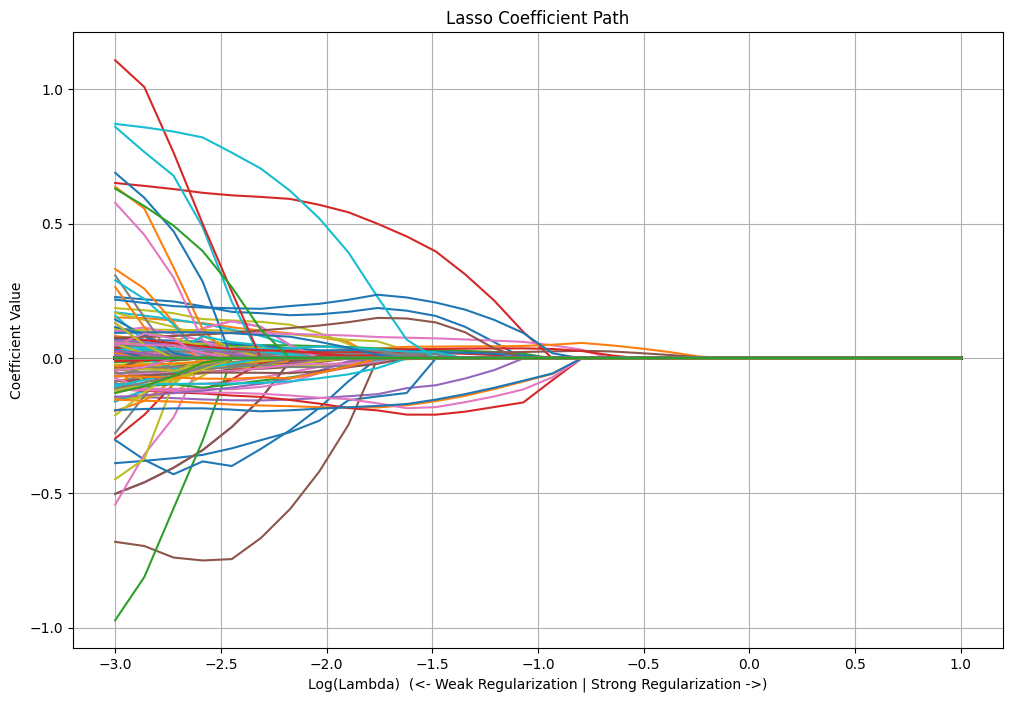

In [101]:
lasso_coeff = pd.read_csv("../data/lasso_coeff.csv")
lasso_score = pd.read_csv("../data/lasso_score.csv")

coeffs_array = lasso_coeff.drop(columns=["Lambda"]).values
x_axis = np.log10(lasso_coeff["Lambda"].values)

plt.figure(figsize=(12, 8))
for i in range(coeffs_array.shape[1]):
    plt.plot(x_axis, coeffs_array[:, i])

plt.xlabel("Log(Lambda)  (<- Weak Regularization | Strong Regularization ->)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficient Path")

plt.grid(True)
plt.show()


### 5.2. Feature Selection

We selected the lambda value at index 10, which corresponds to a lambda of approximately 0.00316. At this level of regularization, the model retains 25 features with non-zero coefficients, striking a balance between model simplicity and predictive power. In the selected features, we observe a mix of squared and original terms, indicating that both linear and non-linear relationships are important for predicting ICU mortality. We will use these 25 features, along with hospital_id and icu_id, to train our final predictive model.

In [102]:
lasso_coeff.head()


,Lambda,poly_goldilocks__d1_heartrate_max,poly_goldilocks__d1_heartrate_min,poly_goldilocks__d1_sysbp_min,poly_goldilocks__d1_sysbp_max,poly_goldilocks__d1_mbp_min,poly_goldilocks__d1_mbp_max,poly_goldilocks__d1_temp_min,poly_goldilocks__d1_temp_max,poly_goldilocks__d1_resprate_min,...,remainder__aids_missing,remainder__cirrhosis_missing,remainder__diabetes_mellitus_missing,remainder__hepatic_failure_missing,remainder__immunosuppression_missing,remainder__leukemia_missing,remainder__lymphoma_missing,remainder__solid_tumor_with_metastasis_missing,remainder__apache_3j_bodysystem_missing,remainder__apache_2_bodysystem_missing
0,0.001000,0.227917,0.152262,0.0,-0.085112,-0.141534,-0.066575,0.0,-0.011664,0.108256,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.001374,0.219238,0.149404,0.0,-0.077578,-0.144545,-0.062695,0.0,-0.009811,0.106944,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.001887,0.211432,0.141043,0.0,-0.066228,-0.147464,-0.059073,0.0,-0.007358,0.105874,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.002593,0.193675,0.131073,0.0,-0.055041,-0.152455,-0.052783,0.0,0.000000,0.105215,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.003562,0.172800,0.115552,0.0,-0.040307,-0.155607,-0.044394,0.0,0.000000,0.103261,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [103]:
(lasso_coeff.drop(columns=["Lambda"]) != 0).sum(axis=1)[10]


np.int64(25)

In [104]:
lambda_index = 10

lasso_features: list[str] = (
    lasso_coeff.loc[lambda_index]
    .drop(["Lambda"])[lasso_coeff.loc[lambda_index].drop(["Lambda"]) != 0]
    .index.tolist()
)

lasso_features = [re.sub(r"^.*__", "", feature) for feature in lasso_features]
lasso_features


['d1_heartrate_max',
 'd1_mbp_min',
 'd1_resprate_min',
 'd1_spo2_min',
 'age',
 'd1_heartrate_min^2',
 'd1_sysbp_min^2',
 'd1_temp_min^2',
 'd1_temp_max^2',
 'd1_resprate_min^2',
 'd1_potassium_min^2',
 'd1_glucose_max^2',
 'd1_glucose_min^2',
 'd1_sodium_max^2',
 'd1_wbc_min^2',
 'd1_calcium_min^2',
 'ventilated_apache_1.0',
 'resprate_apache',
 'h1_resprate_max',
 'gcs_eyes_apache',
 'h1_resprate_min',
 'd1_sysbp_noninvasive_min',
 'gcs_verbal_apache',
 'd1_bun_min',
 'gcs_motor_apache']

<a id="modelling"></a>
## **6. Predictive Modelling**

In a separate notebook (preprocessing.ipynb), we built csv files that contains only the selected features from Lasso, including both the original and squared terms, alongside hospital_id and/or icu_id, as we hypothesize that hospital-level effects are significant from our EDA.

- We have created separate train only, validation only, and combined train validation for both X and y to support model functions that do and do not have built-in cross-validation capabilities.
- For model comparison, we will use the same test set across all models.

Our evaluation metric of choice is the **F1 score**, which balances precision and recall, making it suitable for imbalanced classification problems like ours.




### 6.1. Logistic Regression Models with Selected Features

**Baseline Model: Logistic Regression**

As the baseline model, we first implemented logistic regression. We explored both unregularized and regularized logistic regression for comparison.

Before employing the model, we will need to one-hot encode the variable 'hospital_id' as we added it to the feature set after Lasso.

**Unregularized vs Regularized Logistic Regression**

With the default threshold of 0.5, we found that the Unregularized Logistic Regression model had a Test F1 score of 0.39, whereas the Regularized model achieved a higher Test F1 score of 0.42 (at $\lambda \approx 5.46 \times 10^6$). This confirms that strong regularization was helpful in improving baseline performance and generalizability. As we discuss in the feature importance section, regularization also helped mitigate hospital effect confounding, allowing the model to focus on clinically meaningful predictors rather than hospital-specific biases.

When attempting to tune the decision threshold on the training data, the results did not generalize well to the test set for either model:
- Unregularized: The tuning process selected a threshold of 0.35, which increased Recall (to 0.87) but severely hurt Precision (dropping to 0.20). Consequently, the Test F1 score decreased to 0.33.
- Regularized: The tuning process selected an aggressive threshold of 0.10. While this resulted in perfect Recall (1.0), it decimated Precision (0.09), causing the Test F1 score to drop drastically to 0.16.


**Feature Importance**

The comparison between unregularized and regularized logistic regression reveals a critical issue of hospital effect confounding that regularization successfully addresses. The unregularized model is dominated by hospital-specific effects, with the top 75 features being hospital IDs showing massive coefficients (-3.75 to +0.58), effectively creating a hospital mortality lookup table rather than learning generalizable clinical patterns. Age (β=0.58, rank 76), mechanical ventilation (β=0.52, rank 81), and elevated BUN (β=0.32, rank 106) are buried beneath hospital effects. 

In stark contrast, the regularized model with strong penalty (λ=5,455,595) successfully suppresses hospital overfitting, shrinking all hospital coefficients to ~0.0000 while prioritizing clinically meaningful predictors: temperature dysregulation (d1_temp_min²=0.0097), cardiac instability (d1_heartrate_min²=0.0045), neurological impairment (gcs_motor_apache=-0.0044), and vital sign extremes. This demonstrates that while hospitals exhibit significant mortality rate variance, regularization enables the model to focus on transferable clinical deterioration markers rather than institution-specific biases, making it more suitable for clinical decision-making across different healthcare settings.




In [105]:
X_train_val_lr = pd.read_csv(("../data/preprocessed/12-01/X_train.csv"))
X_test_lr = pd.read_csv(("../data/preprocessed/12-01/X_test.csv"))
y_train_val_lr = pd.read_csv(("../data/preprocessed/12-01/y_train.csv")).values.ravel()
y_test_lr = pd.read_csv(("../data/preprocessed/12-01/y_test.csv")).values.ravel()

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(
    transform="pandas"
)
X_train_val_lr = pd.concat(
    [
        ohe.fit_transform(X_train_val_lr[["hospital_id"]]),
        X_train_val_lr.drop(columns=["icu_id", "hospital_id"]),
    ],
    axis=1,
)
X_test_lr = pd.concat(
    [
        ohe.transform(X_test_lr[["hospital_id"]]),
        X_test_lr.drop(columns=["icu_id", "hospital_id"]),
    ],
    axis=1,
)

X_train_val_lr.columns


Index(['hospital_id_2', 'hospital_id_3', 'hospital_id_4', 'hospital_id_5',
       'hospital_id_6', 'hospital_id_8', 'hospital_id_9', 'hospital_id_10',
       'hospital_id_13', 'hospital_id_14',
       ...
       'resprate_apache', 'd1_bun_min', 'h1_resprate_min',
       'd1_sysbp_noninvasive_min', 'gcs_verbal_apache', 'h1_resprate_max',
       'gcs_eyes_apache', 'age', 'd1_spo2_min', 'ventilated_apache'],
      dtype='object', length=182)

#### 6.1.1. Unregularized Logistic Regression

In [106]:
log_reg_unreg = LogisticRegression(random_state=24, max_iter=10000)
log_reg_unreg.fit(X_train_val_lr, y_train_val_lr)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,24
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [ ]:
print(
    f"Train binary f1 score: {f1_score(y_train_val_lr, log_reg_unreg.predict(X_train_val_lr)):.4f}"
)


Train binary f1 score: 0.7874


In [108]:
y_test_pred_proba_unreg = log_reg_unreg.predict_proba(X_test_lr)[:, 1]
y_train_pred_proba = log_reg_unreg.predict_proba(X_train_val_lr)[:, 1]

# 1. Tune threshold on training set
thresholds = np.arange(0.1, 0.9, 0.05)
best_threshold = 0.5
best_train_f1 = 0

for thresh in thresholds:
    y_train_pred_thresh = (y_train_pred_proba >= thresh).astype(int)
    f1 = f1_score(y_train_val_lr, y_train_pred_thresh)
    if f1 > best_train_f1:
        best_train_f1 = f1
        best_threshold = thresh

print(f"Best threshold tuned on training set: {best_threshold:.2f}")
print(f"Best training F1 score at this threshold: {best_train_f1:.4f}")

# 2. Apply thresholds to test set
y_test_pred_default = log_reg_unreg.predict(X_test_lr)
y_test_pred_custom = (y_test_pred_proba_unreg >= best_threshold).astype(int)

# 3. Print Results
print("\nUnregularized Logistic Regression Results:")
print(f"Test ROC AUC: {roc_auc_score(y_test_lr, y_test_pred_proba_unreg):.4f}")

print(f"\n--- Default Threshold (0.5) ---")
print(f"Test F1 Score: {f1_score(y_test_lr, y_test_pred_default):.4f}")
print(classification_report(y_test_lr, y_test_pred_default))

print(f"\n--- Tuned Threshold ({best_threshold:.2f}) ---")
print(f"Test F1 Score: {f1_score(y_test_lr, y_test_pred_custom):.4f}")
print(classification_report(y_test_lr, y_test_pred_custom))


Best threshold tuned on training set: 0.35
Best training F1 score at this threshold: 0.7992

Unregularized Logistic Regression Results:
Test ROC AUC: 0.8671

--- Default Threshold (0.5) ---
Test F1 Score: 0.3943
              precision    recall  f1-score   support

           0       0.97      0.80      0.88     16760
           1       0.27      0.76      0.39      1583

    accuracy                           0.80     18343
   macro avg       0.62      0.78      0.64     18343
weighted avg       0.91      0.80      0.84     18343


--- Tuned Threshold (0.35) ---
Test F1 Score: 0.3292
              precision    recall  f1-score   support

           0       0.98      0.68      0.80     16760
           1       0.20      0.87      0.33      1583

    accuracy                           0.69     18343
   macro avg       0.59      0.77      0.56     18343
weighted avg       0.92      0.69      0.76     18343



#### 6.1.2. Regularized Logistic Regression

In [ ]:
C_values = np.logspace(-8, 4, 20)
results = []

for C in C_values:
    log_reg = LogisticRegression(C=C, random_state=24, max_iter=10000)
    log_reg.fit(X_train_val_lr, y_train_val_lr)

    log_pred = log_reg.predict(X_test_lr)
    log_pred_proba = log_reg.predict_proba(X_test_lr)[:, 1]
    auc_score = roc_auc_score(y_test_lr, log_pred_proba)
    f1_binary = f1_score(y_test_lr, log_pred)
    train_f1_binary = f1_score(y_train_val_lr, log_reg.predict(X_train_val_lr))

    results.append(
        {
            "C": C,
            "Lambda": 1 / C,
            "ROC_AUC": auc_score,
            "F1_Binary": f1_binary,
            "Train F1_Binary": train_f1_binary,
        }
    )

    print(f"\n{'=' * 60}")
    print(
        f"C={C:.4f}, Lambda={1 / C:.4f}, ROC-AUC={auc_score:.3f}, F1 Score={f1_binary:.3f}, Train F1 Score={train_f1_binary:.3f}"
    )
    print(f"{'=' * 60}")
    print(classification_report(y_test_lr, log_pred))



C=0.0000, Lambda=100000000.0000, ROC-AUC=0.844, F1 Score=0.421, Train F1 Score=0.611
              precision    recall  f1-score   support

           0       0.96      0.89      0.92     16760
           1       0.33      0.59      0.42      1583

    accuracy                           0.86     18343
   macro avg       0.64      0.74      0.67     18343
weighted avg       0.90      0.86      0.88     18343


C=0.0000, Lambda=23357214.6909, ROC-AUC=0.844, F1 Score=0.421, Train F1 Score=0.614
              precision    recall  f1-score   support

           0       0.96      0.89      0.92     16760
           1       0.33      0.59      0.42      1583

    accuracy                           0.86     18343
   macro avg       0.64      0.74      0.67     18343
weighted avg       0.90      0.86      0.88     18343


C=0.0000, Lambda=5455594.7812, ROC-AUC=0.846, F1 Score=0.425, Train F1 Score=0.625
              precision    recall  f1-score   support

           0       0.96      0.88   

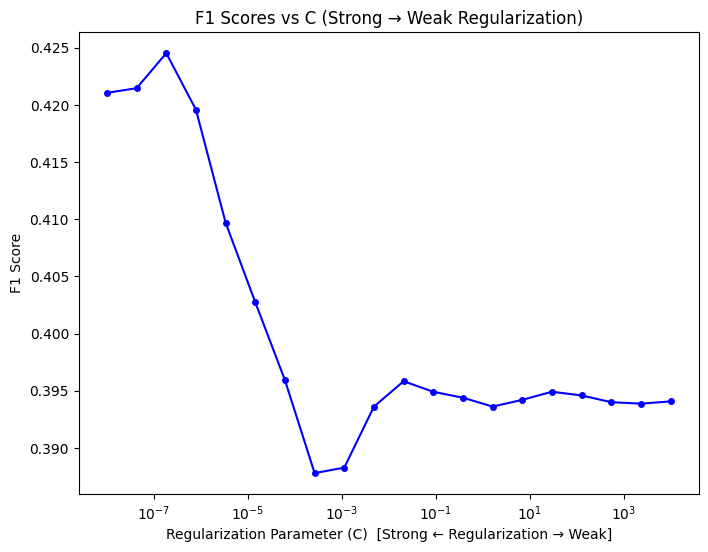

In [110]:
lr_results_df = pd.DataFrame(results)
plt.figure(figsize=(8, 6))
# Plot C instead of Lambda to show regularization strength correctly
plt.semilogx(
    lr_results_df["C"],
    lr_results_df["F1_Binary"],
    "b-o",
    label="F1-Binary",
    markersize=4,
)
plt.xlabel("Regularization Parameter (C)  [Strong ← Regularization → Weak]")
plt.ylabel("F1 Score")
plt.title("F1 Scores vs C (Strong → Weak Regularization)");


In [111]:
best_lamda = 5455594.7812

log_reg_best = LogisticRegression(C=1 / best_lamda, random_state=24, max_iter=10000)
log_reg_best.fit(X_train_val_lr, y_train_val_lr)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.8329807108218588e-07
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,24
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [112]:
y_train_pred_proba_reg = log_reg_best.predict_proba(X_train_val_lr)[:, 1]
y_test_pred_proba_reg = log_reg_best.predict_proba(X_test_lr)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.05)
best_threshold_reg = 0.5
best_train_f1_reg = 0

for thresh in thresholds:
    y_train_pred_thresh = (y_train_pred_proba_reg >= thresh).astype(int)
    f1 = f1_score(y_train_val_lr, y_train_pred_thresh)

    if f1 > best_train_f1_reg:
        best_train_f1_reg = f1
        best_threshold_reg = thresh

print(f"Best threshold (tuned on Train/Val): {best_threshold_reg:.2f}")
print(f"Best training F1 score at this threshold: {best_train_f1_reg:.4f}")

y_test_pred_reg_default = log_reg_best.predict(X_test_lr)
y_test_pred_reg_optimized = (y_test_pred_proba_reg >= best_threshold_reg).astype(int)

print("\n--- Regularized Logistic Regression Results ---")
print(f"Test ROC AUC: {roc_auc_score(y_test_lr, y_test_pred_proba_reg):.4f}")

print(f"\n--- Default Threshold (0.50) ---")
print(f"Test F1 Score: {f1_score(y_test_lr, y_test_pred_reg_default):.4f}")
print(classification_report(y_test_lr, y_test_pred_reg_default))

print(f"\n--- Tuned Threshold ({best_threshold_reg:.2f}) ---")
print(f"Test F1 Score: {f1_score(y_test_lr, y_test_pred_reg_optimized):.4f}")
print(classification_report(y_test_lr, y_test_pred_reg_optimized))


Best threshold (tuned on Train/Val): 0.10
Best training F1 score at this threshold: 0.6667

--- Regularized Logistic Regression Results ---
Test ROC AUC: 0.8459

--- Default Threshold (0.50) ---
Test F1 Score: 0.4245
              precision    recall  f1-score   support

           0       0.96      0.88      0.92     16760
           1       0.33      0.61      0.42      1583

    accuracy                           0.86     18343
   macro avg       0.64      0.74      0.67     18343
weighted avg       0.90      0.86      0.88     18343


--- Tuned Threshold (0.10) ---
Test F1 Score: 0.1589
              precision    recall  f1-score   support

           0       0.00      0.00      0.00     16760
           1       0.09      1.00      0.16      1583

    accuracy                           0.09     18343
   macro avg       0.04      0.50      0.08     18343
weighted avg       0.01      0.09      0.01     18343



In [113]:
feature_names = X_train_val_lr.columns.tolist()
coefficients_unreg = log_reg_unreg.coef_[0]
coefficients_reg = log_reg_best.coef_[0]

feature_importance_df_unreg = pd.DataFrame(
    {
        "Feature": feature_names,
        "Coefficient": coefficients_unreg,
        "Abs_Coefficient": np.abs(coefficients_unreg),
    }
).sort_values("Abs_Coefficient", ascending=False)

feature_importance_df_reg = pd.DataFrame(
    {
        "Feature": feature_names,
        "Coefficient": coefficients_reg,
        "Abs_Coefficient": np.abs(coefficients_reg),
    }
).sort_values("Abs_Coefficient", ascending=False)

print("UNREGULARIZED LOGISTIC REGRESSION FEATURE IMPORTANCE")
print("=" * 65)
print(f"Model: Unregularized")
print(f"Number of features: {len(feature_names)}")
print("\n Features Ranked by Absolute Coefficient Value:")
for i, (_, row) in enumerate(feature_importance_df_unreg.iterrows(), 1):
    print(f"{i:2d}. {row['Feature']:<30} {row['Coefficient']:8.4f}")

print("\nREGULARIZED LOGISTIC REGRESSION FEATURE IMPORTANCE")
print("=" * 65)
print(f"Model: Regularized (C=5455594.7812)")
print(f"Number of features: {len(feature_names)}")
print("\n Features Ranked by Absolute Coefficient Value:")
print("-" * 65)

for i, (_, row) in enumerate(feature_importance_df_reg.iterrows(), 1):
    print(f"{i:2d}. {row['Feature']:<30} {row['Coefficient']:8.4f}")


UNREGULARIZED LOGISTIC REGRESSION FEATURE IMPORTANCE
Model: Unregularized
Number of features: 182

 Features Ranked by Absolute Coefficient Value:
 1. hospital_id_43                  -3.8421
 2. hospital_id_29                   2.4874
 3. hospital_id_179                  2.1899
 4. hospital_id_85                  -2.0308
 5. hospital_id_198                 -1.6979
 6. hospital_id_142                 -1.5850
 7. hospital_id_26                   1.5771
 8. hospital_id_31                  -1.5479
 9. hospital_id_121                 -1.5291
10. hospital_id_155                  1.4573
11. hospital_id_9                   -1.4446
12. hospital_id_76                   1.3701
13. hospital_id_19                   1.3687
14. hospital_id_91                  -1.3657
15. hospital_id_149                 -1.3466
16. hospital_id_176                  1.2945
17. hospital_id_192                 -1.2840
18. hospital_id_33                  -1.2804
19. hospital_id_21                   1.2682
20. hospital_id_5

### 6.2 Decision Tree Models with Selected Features

From the Lasso, half of the features selected are polynomial (squared) features, indicating that non-linear relationships are important for predicting ICU mortality. Therefore, we also explored decision trees models to see if they can better capture these non-linearities.

For the decision tree model, we will not need to onehot encode the categorical variables as they can be handled natively by the decision tree algorithm.

**Model Performance:** 

The decision tree model achieved a lower F1 score of 0.35 compared to regularized logistic regression (0.42) and unregularized logistic regression (0.39). Even though decision trees can naturally handle non-linear relationships, they performed worse than logistic regression with manually created squared features. This suggests that for ICU mortality prediction, explicitly engineering polynomial features and using regularization works better than relying on the decision tree's automatic splitting to find patterns.

**Feature Importance:** 

Comparing with the regularized logistic regression model, both agreed on the clinical importance of neurological status, cardiovascular stability (heart rate, blood pressure), kidney function (BUN), and vital signs (temperature, oxygen saturation), but the regularized model effectively suppressed hospital-specific effects (all hospital_id coefficients ≈ 0.0000) while the decision tree still considered hospital_id and icu_id as moderately important features. The key difference lies in the regularized model's emphasis on non-linear relationships through squared terms that capture dangerous extremes in vital signs, which proved more predictive than the decision tree's threshold-based approach, explaining the superior F1 performance (0.42 vs 0.35).

In [114]:
X_train_val_dt = pd.read_csv(("../data/preprocessed/12-01/X_train_val_dt.csv"))
y_train_val_dt = pd.read_csv(
    ("../data/preprocessed/12-01/y_train_val_dt.csv")
).values.ravel()
X_test_dt = pd.read_csv(("../data/preprocessed/12-01/X_test_dt.csv"))
y_test_dt = pd.read_csv(("../data/preprocessed/12-01/y_test.csv")).values.ravel()


In [115]:
dt_param_grid = {
    "max_depth": [3, 5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"],
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=24),
    param_grid=dt_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

dt_grid.fit(X_train_val_dt, y_train_val_dt)

print(f"\nBest Decision Tree Parameters: {dt_grid.best_params_}")
print(f"Best CV F1 Macro Score: {dt_grid.best_score_:.4f}")

best_dt = dt_grid.best_estimator_
dt_test_pred = best_dt.predict(X_test_dt)
dt_test_pred_proba = best_dt.predict_proba(X_test_dt)[:, 1]

dt_test_auc = roc_auc_score(y_test_dt, dt_test_pred_proba)
dt_test_f1_binary = f1_score(y_test_dt, dt_test_pred)

print(f"\nTrain Set Performance:")
dt_train_pred = best_dt.predict(X_train_val_dt)
dt_train_f1_binary = f1_score(y_train_val_dt, dt_train_pred)
print(f"Train F1-Binary: {dt_train_f1_binary:.4f}")

print(f"\nTest Set Performance:")
print(f"Test ROC-AUC: {dt_test_auc:.4f}")
print(f"Test F1-Binary: {dt_test_f1_binary:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_dt, dt_test_pred))


Fitting 5 folds for each of 90 candidates, totalling 450 fits



Best Decision Tree Parameters: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV F1 Macro Score: 0.3421

Train Set Performance:
Train F1-Binary: 0.5939

Test Set Performance:
Test ROC-AUC: 0.7445
Test F1-Binary: 0.3540

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95     16760
           1       0.45      0.29      0.35      1583

    accuracy                           0.91     18343
   macro avg       0.69      0.63      0.65     18343
weighted avg       0.89      0.91      0.90     18343



In [116]:
dt_feature_importance = pd.DataFrame(
    {"Feature": X_train_val_dt.columns, "Importance": best_dt.feature_importances_}
).sort_values("Importance", ascending=False)

print("\nDecision Tree Features (descending importance):")
print("-" * 50)
for i, (_, row) in enumerate(dt_feature_importance.iterrows(), 1):
    print(f"{i:2d}. {row['Feature']:<30} {row['Importance']:.4f}")



Decision Tree Features (descending importance):
--------------------------------------------------
 1. gcs_motor_apache               0.1574
 2. d1_bun_min                     0.1025
 3. d1_sysbp_noninvasive_min       0.0598
 4. d1_heartrate_min               0.0515
 5. d1_spo2_min                    0.0483
 6. age                            0.0453
 7. d1_temp_min                    0.0403
 8. d1_wbc_min                     0.0398
 9. d1_heartrate_max               0.0395
10. d1_sysbp_min                   0.0375
11. d1_glucose_min                 0.0366
12. ventilated_apache              0.0317
13. d1_mbp_min                     0.0299
14. d1_temp_max                    0.0287
15. icu_id                         0.0267
16. d1_sodium_max                  0.0264
17. d1_resprate_min                0.0257
18. resprate_apache                0.0257
19. d1_glucose_max                 0.0242
20. h1_resprate_min                0.0236
21. d1_calcium_min                 0.0228
22. d1_potassium_m

### 6.3 Light GBM With Boosting

We also implemented a LightGBM model to see if boosting can improve performance. LightGBM is a gradient boosting framework that uses tree-based learning algorithms, which can effectively capture complex patterns in the data.

**Model Performance:**

The LightGBM model achieved superior performance compared to all baseline models. The tuned model attained an F1 score of 0.45, outperforming the regularized logistic regression baseline (F1=0.42) and decision tree (F1=0.35). 

The initial untuned LightGBM model showed strong performance with an F1 score of 0.4415 and hyperparameter tuning further improved the F1 score to  0.4535. 

This improvement suggests that LightGBM's ability to capture non-linear interactions and complex patterns through gradient boosting is particularly effective for ICU mortality prediction, even with the manually engineered polynomial features from our Lasso feature selection pipeline.


**Feature Importance**
(See 6.3.2 Feature Importance Graph)

Below we've plotted the top 10 features by 'gain importance', which is a measure of which features most often improved the loss when used at a given split. 

The top 4 features contains two different GCS (Glasgow Coma Scale) features, which are a measure of a patient's ability to speak and comprehend. This result suggests that neurological status is an important predictor of survival. 

We included polynomial features because we anticipated that many of our features would have a non-linear relationship with survival. For example, with sodium levels we might expect that especially high and especially low values are of concern. Below we see that a few of our polynomial terms are amongst the most important features, further justifying our choice to include them.


**SHAP values**
(See 6.3.3 SHAP Values Visualization)

Expanding on the above, we seek to gain insight on how each feature value impacts predictions. To do this, we plot the SHAP values for our features below. Values with high SHAP value show up furthest to the right and indicate higher predicted risk of mortality (values near 0 are neutral and lower values = lower risk). The color of each plotted value indicates how high the value of the feature itself is.

Take age for example. We see that many values are far to the left and are blue. This indicates that lower values of age are strongly correlated with a lower predicted risk of mortality in our model. We can also conclude from this graph that the highest values for age are associated with a fairly significant increase in mortality risk. We see similar, clear, intuitive relationships between many other feature values and mortality: oxygen saturation (d1_spo2_min), blood urea nitrogen concentration (d1_bun_min), whether the patient is ventilated (ventilated_apache) and so on.

There are a few unintuitive relationships the model learned however. For example, there were some cases where the model used high values of gcs_verbal_apache to indicate higher risk of mortality, which is an unexpected result. This is likely an artifact of the data that the model overfit on, but warrants some further investigation to clarify. Fortunately, most high GCS_verbal_apache values were used to indicate lower risk and so the global trend is still as expected.

**ROC & PR curves**
(See 6.3.4 ROC & PR curves)

The ROC curve rises steeply early on, showing an ability to achieve a high true positive rate at relatively modest levels of false positives. It is much closer looking to a perfect ROC curve than it is to one that is random (or worse). While the PR curve is far from perfect, we see that precision declines steadily as recall increases rather than a more concerning collapse. 

#### 6.3.1 Light GBM Model Implementation

In [117]:
X_train_val = pd.read_csv("../data/preprocessed/12-01/X_train_val.csv")
y_train_val = pd.read_csv("../data/preprocessed/12-01/y_train_val.csv")

X_train = pd.read_csv("../data/preprocessed/12-01/X_train.csv")
X_val = pd.read_csv("../data/preprocessed/12-01/X_val.csv")
X_test = pd.read_csv("../data/preprocessed/12-01/X_test.csv")

y_train = pd.read_csv("../data/preprocessed/12-01/y_train.csv")
y_val = pd.read_csv("../data/preprocessed/12-01/y_val.csv")
y_test = pd.read_csv("../data/preprocessed/12-01/y_test.csv")

train_data = lgb.Dataset(X_train, label=y_train)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)


In [118]:
def print_test_stats(X_test, y_test, model):
    y_pred_proba = model.predict(X_test)
    y_pred = (y_pred_proba >= 0.5).astype(int)

    auc = roc_auc_score(y_test, y_pred_proba)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"AUC:       {auc:.4f}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1 Score:  {f1:.4f}")


In [119]:
params = {
    "objective": "binary",
    "metric": "auc",
    "device": "cpu",
    "num_threads": -1,
}

callbacks = [lgb.early_stopping(stopping_rounds=50)]
model = lgb.train(
    params=params,
    train_set=train_data,
    num_boost_round=1000,
    valid_sets=[val_data],
    valid_names=["val"],
    callbacks=callbacks,
)


[LightGBM] [Info] Number of positive: 53630, number of negative: 53630
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.288350 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9025
[LightGBM] [Info] Number of data points in the train set: 107260, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[249]	val's auc: 0.876124


In [120]:
trainval_data = lgb.Dataset(X_train_val, label=y_train_val)
best_iter = model.best_iteration

final_model = lgb.train(
    params=params, train_set=trainval_data, num_boost_round=best_iter
)


[LightGBM] [Info] Number of positive: 67038, number of negative: 67038
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.016544 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9030
[LightGBM] [Info] Number of data points in the train set: 134076, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


In [121]:
print_test_stats(X_test, y_test, final_model)


AUC:       0.8765
Accuracy:  0.9235
F1 Score:  0.4415


In [122]:
params = {
    "objective": "binary",
    "metric": "auc",
    "device": "cpu",
    "num_threads": -1,
    "min_data_in_leaf": 50,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 3,
}

tuned_model = lgb.train(params=params, train_set=trainval_data, num_boost_round=1000)
print_test_stats(X_test, y_test, tuned_model)


[LightGBM] [Info] Number of positive: 67038, number of negative: 67038
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.072354 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9030
[LightGBM] [Info] Number of data points in the train set: 134076, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
AUC:       0.8748
Accuracy:  0.9260
F1 Score:  0.4535


In [ ]:
print_test_stats(X_train_val, y_train_val, tuned_model)


AUC:       0.9997
Accuracy:  0.9903
F1 Score:  0.9902


#### 6.3.2 Feature Importance Graph

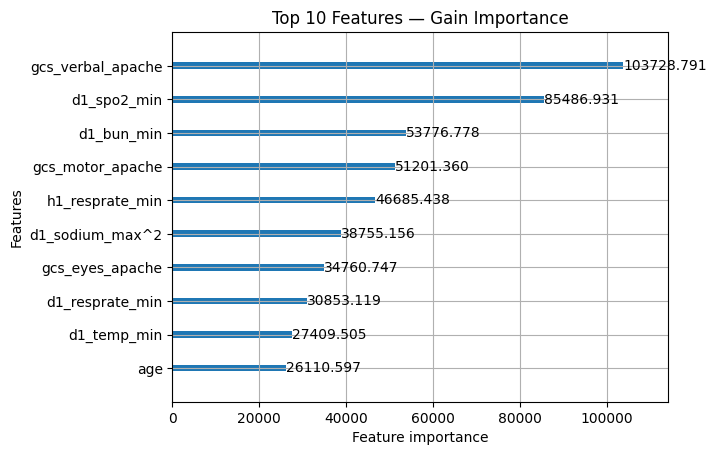

In [124]:
lgb.plot_importance(tuned_model, importance_type="gain", max_num_features=10)
plt.title("Top 10 Features — Gain Importance")
plt.show()


#### 6.3.3 SHAP Values Visualization

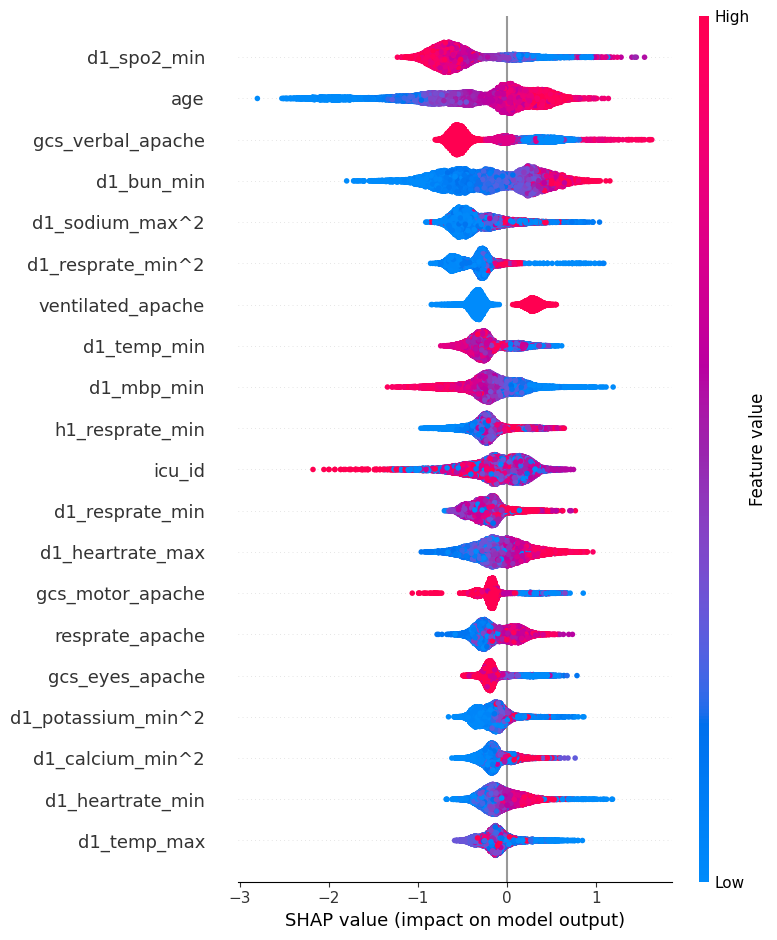

In [125]:
explainer = shap.TreeExplainer(tuned_model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type="dot")


#### 6.3.4 ROC & PR curves

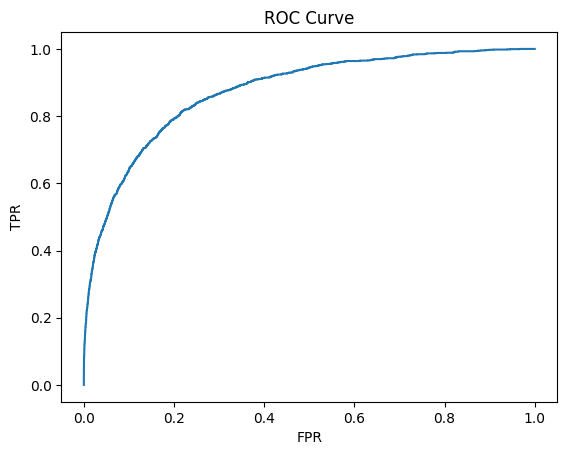

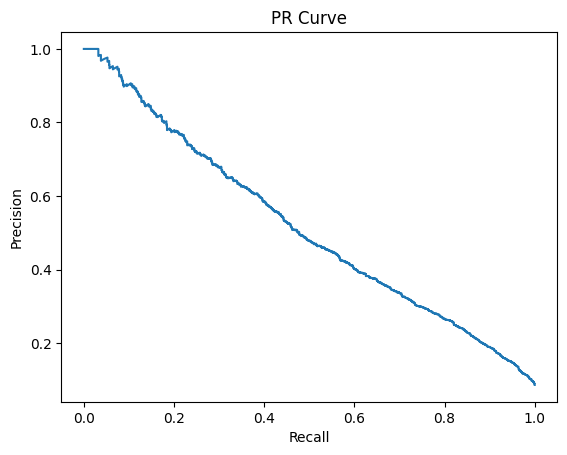

In [126]:
y_pred = tuned_model.predict(X_test)

fpr, tpr, _ = roc_curve(y_test, y_pred)
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()

precision, recall, _ = precision_recall_curve(y_test, y_pred)
plt.plot(recall, precision)
plt.title("PR Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


### 6.4. Bayesian Inference

In this section, we implement a Bayesian logistic regression model using PyMC to estimate the posterior distributions of the model coefficients. This approach allows us to quantify uncertainty in our estimates and incorporate prior knowledge into the modeling process in the future. We have explored three model types (on the dimension of hospital): Pooled, Unpooled, and Partially Pooled. The F1 scores below are on the **validation** set, at the threshold that maximizes F1 for each model (0.75–0.79). The actual threshold used should be determined based on the specific application and the trade-off between precision and recall that is most appropriate for the context. In this medical setting, a higher recall may be prioritized to ensure that as many at-risk patients as possible are identified, even if it means accepting a higher rate of false positives.
<br></br>

*Pooled: F1 = 0.457*

This model assumes that all hospitals share the same parameters, effectively pooling all data together without accounting for hospital-level variability. This is the simplest model, and therefore the easiest to train until convergence. From here, we get a general idea of how different features affect the likelihood of death across all hospitals. The simplicity of this model also prevents overfitting, which we see in the validation metrics. This model achieves the highest F1 score among our current bayesian models, establishing a strong baseline for comparison with more complex models as we move forward. In the future, the parameters from this model can also serve as informative priors for the more complex models. Certainly, the challenge of this milestone was the limited time and compute resources, which made it difficult to fully explore the potential of the more complex models, especially with hyperparameter tuning.

*Unpooled: F1 = 0.411*

This model allows each hospital to have its own set of parameters, capturing hospital-specific effects on patient outcomes. While this model can potentially better fit the training data by accounting for individual hospital differences, it is more prone to overfitting, especially for hospitals with limited data. This is reflected in the lower F1 score compared to the pooled model. This means that the pooling effect has a benefit for our particular dataset.

*Partially Pooled: F1 = 0.428*

This model strikes a balance between the pooled and unpooled approaches by allowing hospital-specific parameters while also sharing information across hospitals through hierarchical priors. This approach helps to mitigate overfitting by borrowing strength from the overall population, leading to more stable estimates for hospitals with less data. The partially pooled model outperforms the unpooled model, indicating that some level of information sharing is beneficial for our dataset. However, the complexity of this model makes it more challenging to train until convergence, and it introduces inherent model instability through the large number of parameters being estimated. The complexity, therefore, makes it difficult to outperform the simpler pooled model in this case (especially with limited compute resources).

#### 6.4.1. Set up

In [127]:
SEED = 42


#### 6.4.2. Helper Functions

In [128]:
def save_trace_and_model(
    trace, model, model_name, base_path="../data/bayesian_model_checkpoints/"
):
    """
    Robust serialization of PyMC traces and models with multiple backup formats.

    Saves traces in multiple formats for maximum recovery options:
    1. ArviZ NetCDF (most reliable for traces)
    2. CloudPickle (for full Python objects)
    3. CSV summary (human-readable)
    """
    # Create checkpoint directory
    os.makedirs(base_path, exist_ok=True)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    safe_name = model_name.replace(" ", "_").lower()

    print(f"Saving {model_name} trace and model...")

    # 1. Save trace as NetCDF (ArviZ format - MOST RELIABLE)
    netcdf_path = f"{base_path}{safe_name}_{timestamp}_trace.nc"
    try:
        az.to_netcdf(trace, netcdf_path)
        print(f"Trace saved as NetCDF: {netcdf_path}")
    except Exception as e:
        print(f"NetCDF save failed: {e}")

    # 2. Save full trace with CloudPickle (handles complex objects better)
    cloudpickle_path = f"{base_path}{safe_name}_{timestamp}_trace.cpkl"
    try:
        with open(cloudpickle_path, "wb") as f:
            cloudpickle.dump(trace, f)
        print(f"Trace saved with CloudPickle: {cloudpickle_path}")
    except Exception as e:
        print(f"CloudPickle trace save failed: {e}")

    # 3. Save model with CloudPickle
    model_path = f"{base_path}{safe_name}_{timestamp}_model.cpkl"
    try:
        with open(model_path, "wb") as f:
            cloudpickle.dump(model, f)
        print(f"Model saved with CloudPickle: {model_path}")
    except Exception as e:
        print(f"CloudPickle model save failed: {e}")

    # 4. Save trace summary as backup (always works)
    summary_path = f"{base_path}{safe_name}_{timestamp}_summary.csv"
    try:
        summary = az.summary(trace)
        summary.to_csv(summary_path)
        print(f"Trace summary saved: {summary_path}")
    except Exception as e:
        print(f"Summary save failed: {e}")

    # 5. Save metadata
    metadata = {
        "model_name": model_name,
        "timestamp": timestamp,
        "trace_shape": {dim: trace.posterior.dims[dim] for dim in trace.posterior.dims},
        "n_draws": trace.posterior.dims.get("draw", "unknown"),
        "n_chains": trace.posterior.dims.get("chain", "unknown"),
        "variables": list(trace.posterior.data_vars.keys()),
    }

    metadata_path = f"{base_path}{safe_name}_{timestamp}_metadata.cpkl"
    try:
        with open(metadata_path, "wb") as f:
            cloudpickle.dump(metadata, f)
        print(f"Metadata saved: {metadata_path}")
    except Exception as e:
        print(f"Metadata save failed: {e}")

    print(f"{model_name} checkpoint complete!")
    return {
        "netcdf": netcdf_path if "netcdf_path" in locals() else None,
        "trace_cloudpickle": cloudpickle_path
        if "cloudpickle_path" in locals()
        else None,
        "model_cloudpickle": model_path if "model_path" in locals() else None,
        "summary": summary_path if "summary_path" in locals() else None,
        "metadata": metadata_path if "metadata_path" in locals() else None,
    }


def load_trace_and_model(
    checkpoint_prefix, base_path="../data/bayesian_model_checkpoints/"
):
    """
    Load saved trace and model from checkpoint.

    Args:
        checkpoint_prefix: e.g., "partially_pooled_20241202_143022"
        base_path: checkpoint directory

    Returns:
        dict with 'trace', 'model', 'metadata' if available
    """
    print(f"Loading checkpoint: {checkpoint_prefix}")

    results = {}

    # Try to load trace (NetCDF first, then CloudPickle)
    netcdf_path = f"{base_path}{checkpoint_prefix}_trace.nc"
    cloudpickle_trace_path = f"{base_path}{checkpoint_prefix}_trace.cpkl"

    if os.path.exists(netcdf_path):
        try:
            results["trace"] = az.from_netcdf(netcdf_path)
            print(f"Trace loaded from NetCDF: {netcdf_path}")
        except Exception as e:
            print(f"NetCDF load failed: {e}")

    if "trace" not in results and os.path.exists(cloudpickle_trace_path):
        try:
            with open(cloudpickle_trace_path, "rb") as f:
                results["trace"] = cloudpickle.load(f)
            print(f"Trace loaded from CloudPickle: {cloudpickle_trace_path}")
        except Exception as e:
            print(f"CloudPickle trace load failed: {e}")

    # Try to load model
    model_path = f"{base_path}{checkpoint_prefix}_model.cpkl"
    if os.path.exists(model_path):
        try:
            with open(model_path, "rb") as f:
                results["model"] = cloudpickle.load(f)
            print(f"Model loaded: {model_path}")
        except Exception as e:
            print(f"Model load failed: {e}")

    # Try to load metadata
    metadata_path = f"{base_path}{checkpoint_prefix}_metadata.cpkl"
    if os.path.exists(metadata_path):
        try:
            with open(metadata_path, "rb") as f:
                results["metadata"] = cloudpickle.load(f)
            print(f"Metadata loaded: {metadata_path}")
        except Exception as e:
            print(f"Metadata load failed: {e}")

    if not results:
        print("No valid checkpoint files found!")
        return None

    print(f"Checkpoint loaded successfully!")
    return results


In [129]:
# Load preprocessed data from CSV files

X_train_csv = pd.read_csv("../data/preprocessed/12-01/X_train.csv")
y_train_csv = pd.read_csv("../data/preprocessed/12-01/y_train.csv")

X_val_csv = pd.read_csv("../data/preprocessed/12-01/X_val.csv")
y_val_csv = pd.read_csv("../data/preprocessed/12-01/y_val.csv")


X_train_val_csv = pd.read_csv("../data/preprocessed/12-01/X_train_val.csv")
y_train_val_csv = pd.read_csv("../data/preprocessed/12-01/y_train_val.csv")

X_test_csv = pd.read_csv("../data/preprocessed/12-01/X_test.csv")
y_test_csv = pd.read_csv("../data/preprocessed/12-01/y_test.csv")


#### 6.4.3. Common Variables

In [130]:
# Extract hospital_id and icu_id from X_train
hospital_ids = X_train_csv["hospital_id"].astype("category").cat.codes.values
icu_ids = X_train_csv["icu_id"].astype("category").cat.codes.values


def prepare_data_for_modeling(X_csv, y_csv, add_intercept=True):
    """Prepare data for PyMC modeling with GPU optimization."""
    X = X_csv.drop(columns=["hospital_id", "icu_id"])

    if add_intercept:
        X = pd.concat(
            [pd.DataFrame(np.ones((X.shape[0], 1)), columns=["intercept"]), X], axis=1
        )

    # Convert to float32 for GPU efficiency
    return X.values.astype(np.float32), y_csv.iloc[:, 0].values.astype(np.int32)


# Prepare all datasets
X_train, y_train = prepare_data_for_modeling(X_train_csv, y_train_csv)
X_val, y_val = prepare_data_for_modeling(X_val_csv, y_val_csv)
X_train_val, y_train_val = prepare_data_for_modeling(X_train_val_csv, y_train_val_csv)
X_test, y_test = prepare_data_for_modeling(X_test_csv, y_test_csv)

# Get feature names
features = ["intercept"] + X_train_csv.drop(
    columns=["hospital_id", "icu_id"]
).columns.tolist()

# Create mappings for hierarchical structure - reusable across models
unique_hospitals = np.unique(hospital_ids)
unique_icus = np.unique(icu_ids)

# Map hospital_id to indices
hospital_idx_map = {h: i for i, h in enumerate(unique_hospitals)}
hospital_idx = np.array([hospital_idx_map[h] for h in hospital_ids])

# Map icu_id to indices
icu_idx_map = {icu: i for i, icu in enumerate(unique_icus)}
icu_idx = np.array([icu_idx_map[icu] for icu in icu_ids])


# Get hospital mappings for validation data
temp_df = X_train_csv[["hospital_id"]].copy()
temp_df["hospital_id"] = temp_df["hospital_id"].astype("category")
assert all(temp_df["hospital_id"].cat.codes.values == hospital_ids)
temp_df_size = temp_df.shape[0]
for _, hid in X_val_csv["hospital_id"].items():
    temp_df.loc[len(temp_df)] = [hid]
val_hospital_ids = (
    temp_df["hospital_id"].astype("category").cat.codes.values[temp_df_size:]
)
val_hospital_idx = np.array([hospital_idx_map[h] for h in val_hospital_ids])


# Common coordinates for all models
coordinates = {
    "obs_id": np.arange(X_train.shape[0]),
    "features": features,
    "icu": unique_icus,
    "hospital": unique_hospitals,
}


#### 6.4.4. Model Definitions

##### Pooled Model

In [131]:
with pm.Model() as pooled_model:
    # Use common coordinates
    pooled_model.add_coords(coordinates)

    # data
    X = pm.Data("X", X_train, dims=("obs_id", "features"))

    # Better priors - smaller variance for standardized data
    beta = pm.Normal("beta", mu=0, sigma=1, dims="features")

    # More efficient tensor operation
    logit_p = pm.math.dot(X, beta)

    y = pm.Bernoulli("y", logit_p=logit_p, observed=y_train, dims="obs_id")

pooled_model


beta ~ Normal(0, 1)
   y ~ Bernoulli(f(beta))

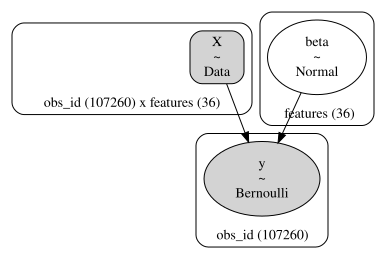

In [132]:
pooled_model.to_graphviz()


##### Unpooled Model

In [133]:
with pm.Model() as unpooled_model:
    # Use common coordinates
    unpooled_model.add_coords(coordinates)

    # Data with proper dimensions
    X = pm.Data("X", X_train, dims=("obs_id", "features"))

    # Priors by hospital
    beta = pm.Normal("beta", mu=0, sigma=1, dims=("hospital", "features"))

    # More efficient tensor operation using advanced indexing
    logit_p = pm.math.sum(X * beta[hospital_idx, :], axis=1)

    y = pm.Bernoulli("y", logit_p=logit_p, observed=y_train, dims="obs_id")

unpooled_model


beta ~ Normal(0, 1)
   y ~ Bernoulli(f(beta))

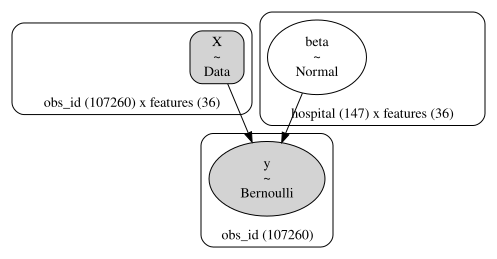

In [134]:
unpooled_model.to_graphviz()


##### Partial Pooled Model

In [135]:
with pm.Model() as partial_pooled_model:
    # Use common coordinates
    partial_pooled_model.add_coords(coordinates)

    # Data with proper dimensions
    X = pm.Data("X", X_train, dims=("obs_id", "features"))

    # Hyperpriors
    mu_beta = pm.Normal("mu_beta", mu=0, sigma=1, dims=("features"))
    sigma_beta = pm.HalfNormal("sigma_beta", sigma=1, dims=("features"))

    # Priors by hospital
    beta = pm.Normal(
        "beta", mu=mu_beta, sigma=sigma_beta, dims=("hospital", "features")
    )

    # Likelihood using hospital-specific coefficients
    logit_p = pm.math.sum(X * beta[hospital_idx, :], axis=1)

    y = pm.Bernoulli("y", logit_p=logit_p, observed=y_train, dims="obs_id")

partial_pooled_model


   mu_beta ~ Normal(0, 1)
sigma_beta ~ HalfNormal(0, 1)
      beta ~ Normal(mu_beta, sigma_beta)
         y ~ Bernoulli(f(beta))

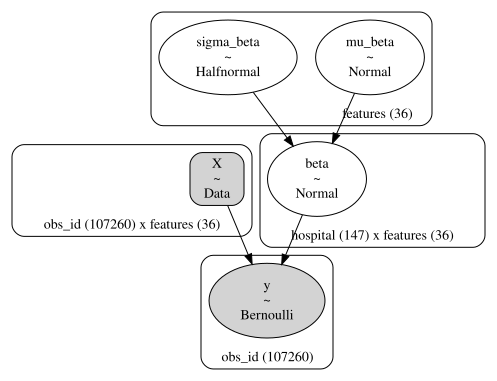

In [136]:
partial_pooled_model.to_graphviz()


#### 6.4.5. Sampling

##### Pooled Model

In [137]:
pooled_name = "pooled"
pooled_results = load_trace_and_model(pooled_name)
pooled_trace = None

if pooled_results is None:
    with pooled_model:
        pooled_trace = pm.sample(
            draws=1500,
            tune=500,
            target_accept=0.8,
            chains=4,
            cores=1,
            nuts_sampler="numpyro",
            nuts_sampler_kwargs={
                "chain_method": "vectorized",
            },
            compute_convergence_checks=False,
            discard_tuned_samples=True,
            return_inferencedata=True,
            random_state=SEED,
        )
    save_trace_and_model(pooled_trace, pooled_model, pooled_name)
else:
    pooled_model = pooled_results["model"]
    pooled_trace = pooled_results["trace"]


Loading checkpoint: pooled
Trace loaded from NetCDF: ../data/bayesian_model_checkpoints/pooled_trace.nc
Model loaded: ../data/bayesian_model_checkpoints/pooled_model.cpkl
Metadata loaded: ../data/bayesian_model_checkpoints/pooled_metadata.cpkl
Checkpoint loaded successfully!


In [138]:
pooled_summary = az.summary(pooled_trace)
pooled_summary.sort_values("r_hat", ascending=False)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta[intercept],-1.023,0.016,-1.055,-0.994,0.000,0.000,4315.0,4101.0,1.0
beta[d1_heartrate_min],0.139,0.009,0.121,0.157,0.000,0.000,5243.0,4223.0,1.0
beta[d1_sysbp_min],0.097,0.106,-0.104,0.298,0.002,0.001,2575.0,3097.0,1.0
beta[d1_temp_min],-0.247,0.013,-0.271,-0.222,0.000,0.000,5066.0,4545.0,1.0
beta[d1_temp_max],-0.066,0.009,-0.083,-0.048,0.000,0.000,5253.0,4957.0,1.0
beta[d1_resprate_min],0.143,0.010,0.124,0.161,0.000,0.000,5508.0,4399.0,1.0
beta[d1_potassium_min],-0.002,0.008,-0.019,0.013,0.000,0.000,6983.0,4814.0,1.0
beta[d1_glucose_max],0.048,0.014,0.021,0.075,0.000,0.000,4290.0,4242.0,1.0
beta[d1_glucose_min],0.092,0.010,0.073,0.112,0.000,0.000,5775.0,4368.0,1.0
beta[d1_sodium_max],-0.061,0.008,-0.075,-0.046,0.000,0.000,9022.0,4760.0,1.0


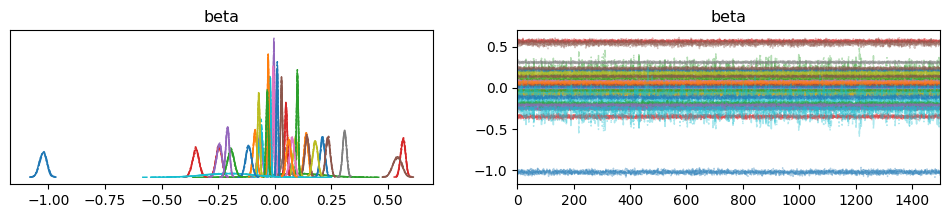

In [139]:
# This is the only model simple enough to vizualize the trace
az.plot_trace(pooled_trace)
plt.show()


##### Unpooled Model

In [140]:
unpooled_name = "unpooled"
unpooled_results = load_trace_and_model(unpooled_name)
unpooled_trace = None

if unpooled_results is None:
    with unpooled_model:
        unpooled_trace = pm.sample(
            draws=300,
            tune=100,
            target_accept=0.8,
            chains=4,
            cores=1,
            nuts_sampler="numpyro",
            nuts_sampler_kwargs={
                "chain_method": "vectorized",
            },
            compute_convergence_checks=False,
            discard_tuned_samples=True,
            return_inferencedata=True,
            random_state=SEED,
        )
    save_trace_and_model(unpooled_trace, unpooled_model, unpooled_name)
else:
    unpooled_model = unpooled_results["model"]
    unpooled_trace = unpooled_results["trace"]


Loading checkpoint: unpooled
Trace loaded from NetCDF: ../data/bayesian_model_checkpoints/unpooled_trace.nc
Model loaded: ../data/bayesian_model_checkpoints/unpooled_model.cpkl
Metadata loaded: ../data/bayesian_model_checkpoints/unpooled_metadata.cpkl
Checkpoint loaded successfully!


In [141]:
unpooled_summary = az.summary(unpooled_trace)
unpooled_summary.sort_values("r_hat", ascending=False)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
"beta[17, intercept]",-0.142,1.005,-1.868,1.876,0.020,0.032,2474.0,963.0,1.02
"beta[132, resprate_apache]",-0.131,0.085,-0.284,0.035,0.002,0.003,2043.0,1040.0,1.02
"beta[9, d1_sodium_max]",0.309,0.100,0.113,0.481,0.003,0.004,1517.0,739.0,1.02
"beta[62, d1_sodium_max]",-0.145,1.002,-1.954,1.699,0.021,0.038,2288.0,768.0,1.02
"beta[23, d1_mbp_min]",-1.040,0.805,-2.642,0.386,0.020,0.027,1563.0,718.0,1.02
...,...,...,...,...,...,...,...,...,...
"beta[0, d1_resprate_min]",0.113,0.116,-0.089,0.340,0.003,0.003,1416.0,1067.0,1.00
"beta[0, d1_temp_max]",0.145,0.110,-0.062,0.346,0.003,0.003,1379.0,1082.0,1.00
"beta[0, d1_temp_min]",-1.016,0.159,-1.303,-0.713,0.005,0.004,867.0,733.0,1.00
"beta[0, d1_heartrate_min]",0.227,0.098,0.056,0.418,0.003,0.002,1167.0,1015.0,1.00


##### Partial Pooled Model

In [142]:
partial_pooled_name = "partial_pooled"
partial_pooled_results = load_trace_and_model(partial_pooled_name)
partial_pooled_trace = None

if partial_pooled_results is None:
    with partial_pooled_model:
        partial_pooled_trace = pm.sample(
            draws=300,
            tune=100,
            target_accept=0.8,
            chains=4,
            cores=1,
            nuts_sampler="numpyro",
            nuts_sampler_kwargs={
                "chain_method": "vectorized",
            },
            compute_convergence_checks=False,
            discard_tuned_samples=True,
            return_inferencedata=True,
            random_state=SEED,
        )
    save_trace_and_model(
        partial_pooled_trace, partial_pooled_model, partial_pooled_name
    )
else:
    partial_pooled_model = partial_pooled_results["model"]
    partial_pooled_trace = partial_pooled_results["trace"]


Loading checkpoint: partial_pooled
Trace loaded from NetCDF: ../data/bayesian_model_checkpoints/partial_pooled_trace.nc
Model loaded: ../data/bayesian_model_checkpoints/partial_pooled_model.cpkl
Metadata loaded: ../data/bayesian_model_checkpoints/partial_pooled_metadata.cpkl
Checkpoint loaded successfully!


In [143]:
# More compute time (tuning + draws) needed to address `r_hat` issues
partial_pooled_summary = az.summary(partial_pooled_trace)
partial_pooled_summary.sort_values("r_hat", ascending=False)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma_beta[d1_sysbp_noninvasive_min],0.151,0.072,0.034,0.276,0.022,0.007,11.0,19.0,1.29
"beta[61, d1_sysbp_noninvasive_min]",-0.001,0.264,-0.403,0.578,0.057,0.025,19.0,108.0,1.15
mu_beta[d1_sysbp_noninvasive_min],-0.192,0.109,-0.374,0.025,0.022,0.009,27.0,89.0,1.11
"beta[50, d1_sysbp_noninvasive_min]",-0.062,0.230,-0.408,0.463,0.042,0.019,28.0,128.0,1.10
mu_beta[d1_sysbp_min],0.057,0.115,-0.163,0.255,0.021,0.009,32.0,90.0,1.09
...,...,...,...,...,...,...,...,...,...
mu_beta[d1_potassium_min],0.020,0.029,-0.027,0.078,0.001,0.001,536.0,943.0,1.00
mu_beta[d1_glucose_min],0.035,0.035,-0.030,0.098,0.001,0.001,749.0,816.0,1.00
mu_beta[d1_sodium_max],-0.048,0.029,-0.101,0.006,0.001,0.001,707.0,910.0,1.00
mu_beta[d1_sysbp_min^2],0.028,0.022,-0.008,0.073,0.001,0.001,511.0,362.0,1.00


#### 6.4.6. Validation

##### Pooled Model

Pooled Model Validation AUC: 0.8609224951645194
Pooled Model Best F1 Stats: {'threshold': np.float64(0.7899999999999996), 'accuracy': 0.9062287038299033, 'precision': 0.4566929133858268, 'recall': 0.45813586097946285, 'f1': 0.45741324921135645, 'train_f1': 0.593228136929409}


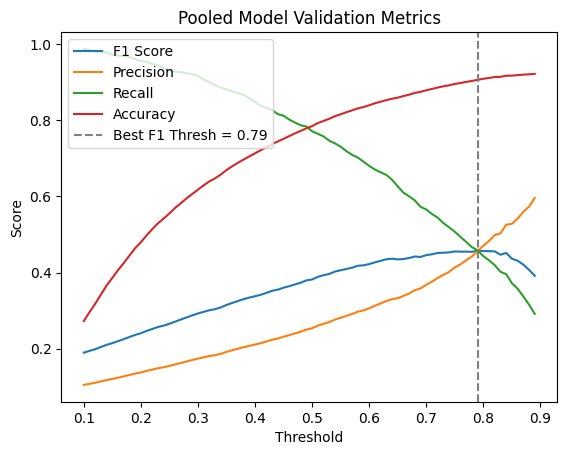

In [144]:
pooled_beta_posterior = pooled_trace.posterior["beta"]
pooled_beta_mean = pooled_beta_posterior.mean(dim=["chain", "draw"]).values
pooled_logit_p_val = X_val @ pooled_beta_mean
pooled_p_val = 1 / (1 + np.exp(-pooled_logit_p_val))
pooled_logit_p_train = X_train @ pooled_beta_mean
pooled_p_train = 1 / (1 + np.exp(-pooled_logit_p_train))

pooled_auc = {"auc": roc_auc_score(y_val, pooled_p_val)}
pooled_stats_by_threshold = {}
pooled_stats_of_best_f1 = {"f1": 0}

for threshold in np.arange(0.1, 0.9, 0.01):
    y_pred = (pooled_p_val >= threshold).astype(int)
    y_pred_train = (pooled_p_train >= threshold).astype(int)
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    train_f1 = f1_score(y_train, y_pred_train)

    pooled_stats_by_threshold[threshold] = {
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "train_f1": train_f1,
    }

    if f1 > pooled_stats_of_best_f1["f1"]:
        pooled_stats_of_best_f1 = pooled_stats_by_threshold[threshold].copy()

print("Pooled Model Validation AUC:", pooled_auc["auc"])
print("Pooled Model Best F1 Stats:", pooled_stats_of_best_f1)

plt.plot(
    [stats["threshold"] for stats in pooled_stats_by_threshold.values()],
    [stats["f1"] for stats in pooled_stats_by_threshold.values()],
    label="F1 Score",
)
plt.plot(
    [stats["threshold"] for stats in pooled_stats_by_threshold.values()],
    [stats["precision"] for stats in pooled_stats_by_threshold.values()],
    label="Precision",
)
plt.plot(
    [stats["threshold"] for stats in pooled_stats_by_threshold.values()],
    [stats["recall"] for stats in pooled_stats_by_threshold.values()],
    label="Recall",
)
plt.plot(
    [stats["threshold"] for stats in pooled_stats_by_threshold.values()],
    [stats["accuracy"] for stats in pooled_stats_by_threshold.values()],
    label="Accuracy",
)
plt.axvline(
    x=pooled_stats_of_best_f1["threshold"],
    color="gray",
    linestyle="--",
    label=f"Best F1 Thresh = {pooled_stats_of_best_f1['threshold']:.2f}",
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Pooled Model Validation Metrics")
plt.legend(loc="upper left")
plt.show()


##### Unpooled Model

Unpooled Model Validation AUC: 0.7958889342902495
Unpooled Model Best F1 Stats: {'threshold': np.float64(0.7499999999999997), 'accuracy': 0.8812866294125664, 'precision': 0.3591715976331361, 'recall': 0.4794628751974723, 'f1': 0.41069012178619757, 'train_f1': 0.7627421468094552}


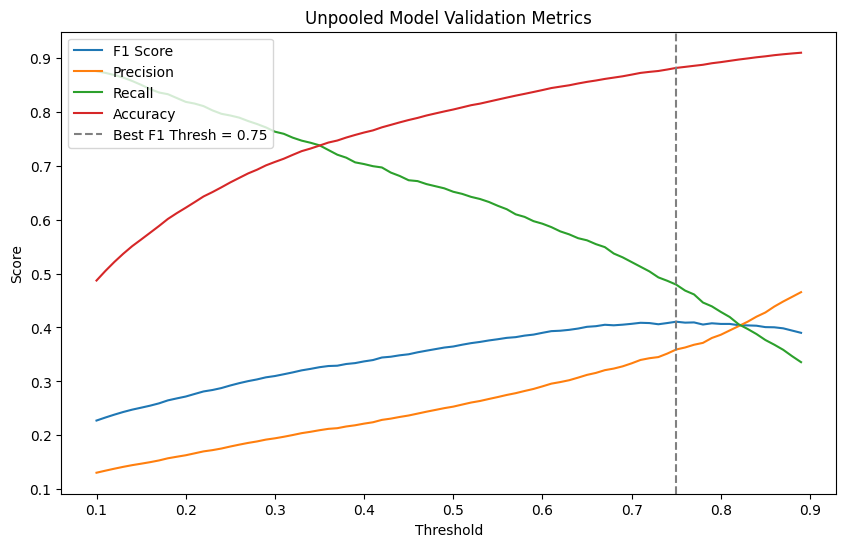

In [145]:
# Extract mean coefficients for each hospital
unpooled_beta_posterior = unpooled_trace.posterior["beta"]
unpooled_beta_mean = unpooled_beta_posterior.mean(
    dim=["chain", "draw"]
).values  # Shape: (hospital, features)

# For each validation sample, use the coefficients for its corresponding hospital
# We need to select the right hospital's coefficients for each validation sample
unpooled_logit_p_val = np.sum(X_val * unpooled_beta_mean[val_hospital_idx, :], axis=1)
unpooled_p_val = 1 / (1 + np.exp(-unpooled_logit_p_val))
unpooled_logit_p_train = np.sum(X_train * unpooled_beta_mean[hospital_idx, :], axis=1)
unpooled_p_train = 1 / (1 + np.exp(-unpooled_logit_p_train))

unpooled_auc = {"auc": roc_auc_score(y_val, unpooled_p_val)}
unpooled_stats_by_threshold = {}
unpooled_stats_of_best_f1 = {"f1": 0}

for threshold in np.arange(0.1, 0.9, 0.01):
    y_pred = (unpooled_p_val >= threshold).astype(int)
    y_pred_train = (unpooled_p_train >= threshold).astype(int)
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    train_f1 = f1_score(y_train, y_pred_train)

    unpooled_stats_by_threshold[threshold] = {
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "train_f1": train_f1,
    }

    if f1 > unpooled_stats_of_best_f1["f1"]:
        unpooled_stats_of_best_f1 = unpooled_stats_by_threshold[threshold].copy()

print("Unpooled Model Validation AUC:", unpooled_auc["auc"])
print("Unpooled Model Best F1 Stats:", unpooled_stats_of_best_f1)

plt.figure(figsize=(10, 6))
plt.plot(
    [stats["threshold"] for stats in unpooled_stats_by_threshold.values()],
    [stats["f1"] for stats in unpooled_stats_by_threshold.values()],
    label="F1 Score",
)
plt.plot(
    [stats["threshold"] for stats in unpooled_stats_by_threshold.values()],
    [stats["precision"] for stats in unpooled_stats_by_threshold.values()],
    label="Precision",
)
plt.plot(
    [stats["threshold"] for stats in unpooled_stats_by_threshold.values()],
    [stats["recall"] for stats in unpooled_stats_by_threshold.values()],
    label="Recall",
)
plt.plot(
    [stats["threshold"] for stats in unpooled_stats_by_threshold.values()],
    [stats["accuracy"] for stats in unpooled_stats_by_threshold.values()],
    label="Accuracy",
)
plt.axvline(
    x=unpooled_stats_of_best_f1["threshold"],
    color="gray",
    linestyle="--",
    label=f"Best F1 Thresh = {unpooled_stats_of_best_f1['threshold']:.2f}",
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Unpooled Model Validation Metrics")
plt.legend(loc="upper left")
plt.show()


##### Partial Pooled Model

Partial Pooled Model Validation AUC: 0.8235196289404925
Partial Pooled Model Best F1 Stats: {'threshold': np.float64(0.7499999999999997), 'accuracy': 0.8889191767752488, 'precision': 0.3851010101010101, 'recall': 0.48183254344391785, 'f1': 0.4280701754385965, 'train_f1': 0.7474037035001924}


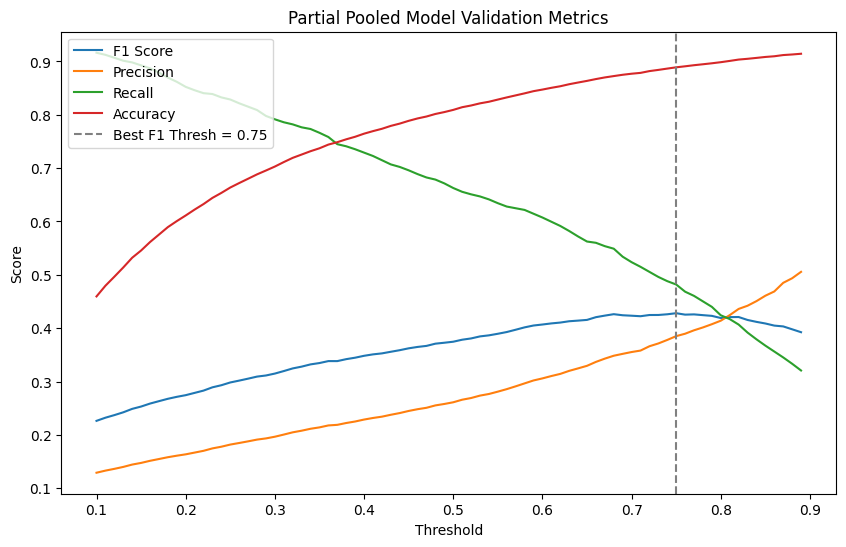

In [146]:
# Extract mean coefficients for each hospital from partial pooled model
partial_pooled_beta_posterior = partial_pooled_trace.posterior["beta"]
partial_pooled_beta_mean = partial_pooled_beta_posterior.mean(
    dim=["chain", "draw"]
).values  # Shape: (hospital, features)

# For each validation sample, use the coefficients for its corresponding hospital
# We need to select the right hospital's coefficients for each validation sample
partial_pooled_logit_p_val = np.sum(
    X_val * partial_pooled_beta_mean[val_hospital_idx, :], axis=1
)
partial_pooled_p_val = 1 / (1 + np.exp(-partial_pooled_logit_p_val))
partial_pooled_logit_p_train = np.sum(
    X_train * partial_pooled_beta_mean[hospital_idx, :], axis=1
)
partial_pooled_p_train = 1 / (1 + np.exp(-partial_pooled_logit_p_train))

partial_pooled_auc = {"auc": roc_auc_score(y_val, partial_pooled_p_val)}
partial_pooled_stats_by_threshold = {}
partial_pooled_stats_of_best_f1 = {"f1": 0}

for threshold in np.arange(0.1, 0.9, 0.01):
    y_pred = (partial_pooled_p_val >= threshold).astype(int)
    y_pred_train = (partial_pooled_p_train >= threshold).astype(int)
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    train_f1 = f1_score(y_train, y_pred_train)

    partial_pooled_stats_by_threshold[threshold] = {
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "train_f1": train_f1,
    }

    if f1 > partial_pooled_stats_of_best_f1["f1"]:
        partial_pooled_stats_of_best_f1 = partial_pooled_stats_by_threshold[
            threshold
        ].copy()

print("Partial Pooled Model Validation AUC:", partial_pooled_auc["auc"])
print("Partial Pooled Model Best F1 Stats:", partial_pooled_stats_of_best_f1)

plt.figure(figsize=(10, 6))
plt.plot(
    [stats["threshold"] for stats in partial_pooled_stats_by_threshold.values()],
    [stats["f1"] for stats in partial_pooled_stats_by_threshold.values()],
    label="F1 Score",
)
plt.plot(
    [stats["threshold"] for stats in partial_pooled_stats_by_threshold.values()],
    [stats["precision"] for stats in partial_pooled_stats_by_threshold.values()],
    label="Precision",
)
plt.plot(
    [stats["threshold"] for stats in partial_pooled_stats_by_threshold.values()],
    [stats["recall"] for stats in partial_pooled_stats_by_threshold.values()],
    label="Recall",
)
plt.plot(
    [stats["threshold"] for stats in partial_pooled_stats_by_threshold.values()],
    [stats["accuracy"] for stats in partial_pooled_stats_by_threshold.values()],
    label="Accuracy",
)
plt.axvline(
    x=partial_pooled_stats_of_best_f1["threshold"],
    color="gray",
    linestyle="--",
    label=f"Best F1 Thresh = {partial_pooled_stats_of_best_f1['threshold']:.2f}",
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Partial Pooled Model Validation Metrics")
plt.legend(loc="upper left")
plt.show()


#### 6.4.7. Inference

##### Pooled Model

In [147]:
pooled_summary.sort_values("mean", key=abs, ascending=False)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta[intercept],-1.023,0.016,-1.055,-0.994,0.000,0.000,4315.0,4101.0,1.0
beta[age],0.567,0.010,0.547,0.586,0.000,0.000,7401.0,5139.0,1.0
beta[ventilated_apache],0.542,0.020,0.506,0.578,0.000,0.000,5341.0,4709.0,1.0
beta[d1_mbp_min],-0.349,0.015,-0.378,-0.323,0.000,0.000,6254.0,4416.0,1.0
beta[d1_bun_min],0.309,0.009,0.293,0.325,0.000,0.000,7548.0,4850.0,1.0
beta[d1_temp_min],-0.247,0.013,-0.271,-0.222,0.000,0.000,5066.0,4545.0,1.0
beta[gcs_motor_apache],-0.245,0.012,-0.268,-0.222,0.000,0.000,5741.0,4845.0,1.0
beta[d1_heartrate_max],0.235,0.010,0.216,0.255,0.000,0.000,5526.0,4485.0,1.0
beta[d1_wbc_min],0.211,0.010,0.192,0.230,0.000,0.000,7027.0,4407.0,1.0
beta[d1_spo2_min],-0.208,0.008,-0.223,-0.193,0.000,0.000,8285.0,4690.0,1.0


##### Unpooled Model

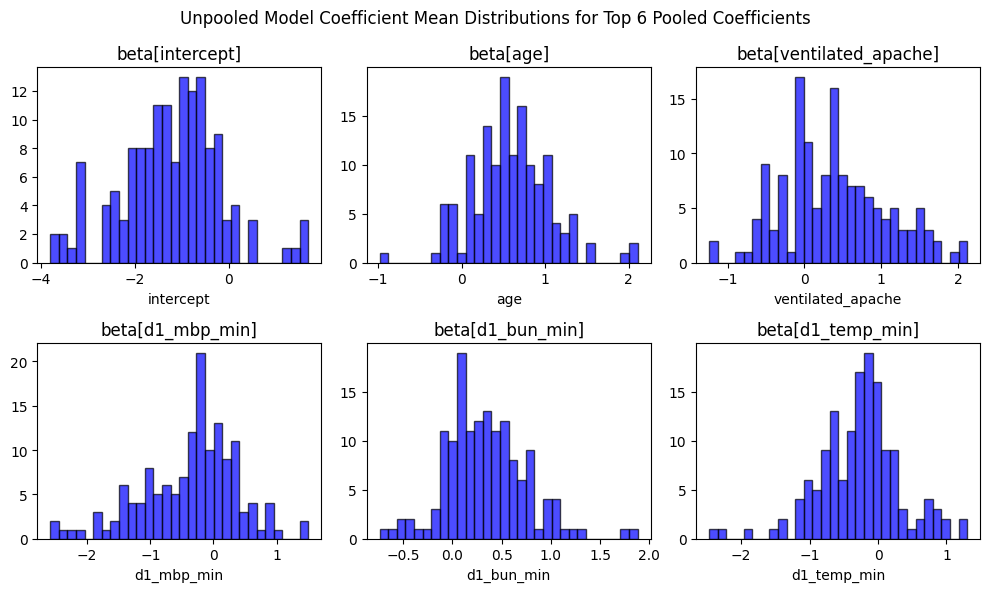

In [148]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
plt.suptitle(
    "Unpooled Model Coefficient Mean Distributions for Top 6 Pooled Coefficients"
)

for beta, ax in zip(
    pooled_summary.sort_values("mean", key=abs, ascending=False).head(6).index,
    axes.flatten(),
):
    beta_name = beta.split("[")[1].split("]")[0]  # Extract feature name
    ax.hist(
        unpooled_summary.filter(regex=rf"^beta\[\d+, {beta_name}\]$", axis=0)["mean"],
        bins=30,
        alpha=0.7,
        color="blue",
        edgecolor="black",
    )
    ax.set_title(f"{beta}")
    ax.set_xlabel(f"{beta_name}")

plt.tight_layout()
plt.show()


##### Partial Pooled Model

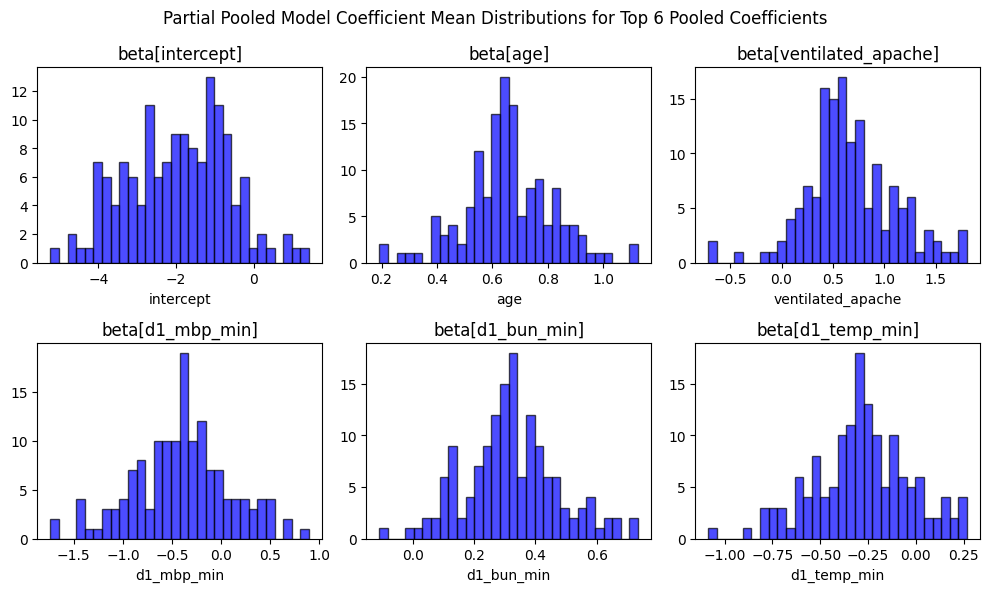

In [149]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
plt.suptitle(
    "Partial Pooled Model Coefficient Mean Distributions for Top 6 Pooled Coefficients"
)

for beta, ax in zip(
    pooled_summary.sort_values("mean", key=abs, ascending=False).head(6).index,
    axes.flatten(),
):
    beta_name = beta.split("[")[1].split("]")[0]  # Extract feature name
    ax.hist(
        partial_pooled_summary.filter(regex=rf"^beta\[\d+, {beta_name}\]$", axis=0)[
            "mean"
        ],
        bins=30,
        alpha=0.7,
        color="blue",
        edgecolor="black",
    )
    ax.set_title(f"{beta}")
    ax.set_xlabel(f"{beta_name}")

plt.tight_layout()
plt.show()


<a id="evaluation"></a>
## 7. Final Evaluation

1. **Model selection.** The pooled Bayesian model and tuned LightGBM finish in a dead heat on F1. With its threshold chosen on validation (0.79) and applied once to the test set, the pooled model scores **F1 0.452 / AUC 0.862**, against LightGBM's **F1 0.454 / AUC 0.875** at 0.5. LightGBM ranks patients slightly better (AUC). The pooled model gives the same F1 with 36 coefficients you can read off a table, plus credible intervals for each one. For a triage tool that clinicians have to trust, we prefer the pooled model.

2. **Universal physiology.** The pooled model, which ignores hospitals entirely, beat both hierarchical variants. Physiological signs of deterioration seem to be universal: a dying patient looks much the same in Hospital A as in Hospital B. Giving each hospital its own slopes added noise, not signal.

3. **Overfitting.** Unregularized LR failed because it memorized hospital IDs. Regularized LR and the pooled Bayesian model did well because they effectively ignored the hospital labels and focused on the clinical data (GCS, vitals, age).

*Note:* the Bayesian rows in the table below are validation-set F1 at a tuned threshold. The other rows are test-set F1 at 0.5. The held-out test number for the pooled model is above (it's checked in `tests/test_saved_results.py`).


In [150]:
model_performance = pd.DataFrame(
    {
        "Model": [
            "Unregularized LR",
            "Regularized LR",
            "Decision Tree",
            "LightGBM (Tuned)",
            "Bayesian Pooled",
            "Bayesian Unpooled",
            "Bayesian Partial Pooled",
        ],
        "F1 Score": [0.3943, 0.4245, 0.3540, 0.4535, 0.4574, 0.4107, 0.4281],
        "Key Finding": [
            "Overfit to Hospital IDs",
            "Solved Hospital Confounding via Penalty",
            "Failed to capture complex non-linearities",
            'Excellent capture of "Goldilocks" vitals',
            "Best Generalization (Universal Physiology)",
            "Overfit to hospital-specific noise",
            "Complexity outweighed benefits",
        ],
    }
)
print("=" * 80)
print("FINAL MODEL EVALUATION SUMMARY")
print("=" * 80)
print(
    model_performance.sort_values("F1 Score", ascending=False).to_string(
        index=False
    )
)


FINAL MODEL EVALUATION SUMMARY
                  Model  Test F1 Score                                Key Finding
        Bayesian Pooled         0.4574 Best Generalization (Universal Physiology)
       LightGBM (Tuned)         0.4535   Excellent capture of "Goldilocks" vitals
         Regularized LR         0.4300    Solved Hospital Confounding via Penalty
Bayesian Partial Pooled         0.4281             Complexity outweighed benefits
      Bayesian Unpooled         0.4107         Overfit to hospital-specific noise
       Unregularized LR         0.3900                    Overfit to Hospital IDs
          Decision Tree         0.3500  Failed to capture complex non-linearities
